<a href="https://colab.research.google.com/github/rudrascience/Loan_Default_Analysis/blob/main/EDA_Loan_Default_Analysis_Rudrajit_Das_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [22]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All"
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# 1. Setup and Importing Libraries

In [23]:
import os, sys, json, warnings
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve, roc_curve,
                             recall_score, precision_score, fbeta_score, brier_score_loss, confusion_matrix)
from IPython.display import display

warnings.filterwarnings('ignore', category=FutureWarning)

random_state = 42
id_candidates = ['LoanID']

pd.set_option('display.max_columns', 100)
pd.set_option('display.width', 140)

print('Python:', sys.version.split()[0])
print('Working directory:', os.getcwd())

try:
    import statsmodels.api as sm
    HAS_SM = True
except ImportError:
    HAS_SM = False
try:
    import lightgbm as lgb
    HAS_LGB = True
except ImportError:
    HAS_LGB = False
try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False
print(f"statsmodels={HAS_SM}  lightgbm={HAS_LGB}  shap={HAS_SHAP}")

Python: 3.13.16
Working directory: /content
statsmodels=True  lightgbm=True  shap=True


# 2. Loading the CSV data

In [24]:
df = pd.read_csv('/content/Loan_default.csv', low_memory=False)
cfg = dict(
    data_path=['/content/Loan_default.csv'],
    target='Default',
    target_recall=0.80,        # business constraint: catch >= 80% of defaulters
    cost_fn=5.0, cost_fp=1.0,  # relative cost of missing a default vs wrongly flagging a good loan (it is set with credit-policy team)
    test_size=0.20, val_size=0.20,
    n_search_iter=15, cv_folds=3,
    n_boot=300,
    protected=['MaritalStatus'],   # ECOA-sensitive: used for fairness audit; modeled with/without
    pricing_leak_suspect=['InterestRate'], # priced AFTER underwriting risk assessment -> potential leakage/circularity
)

In [25]:
# Normalize column names conservatively for robust matching, while retaining source names.
original_columns = df.columns.tolist()
normalized_lookup = {str(c).strip().lower(): c for c in df.columns}

# Reference the defined target from cfg and id_candidates list
target_candidates = [cfg['target']]

target_col = next(
    (normalized_lookup[c.lower()] for c in target_candidates if c.lower() in normalized_lookup),
    None
)
if target_col is None:
    print('Available columns:', original_columns)
    raise KeyError(
        'Could not identify the target. Set target_col manually to the column representing loan default.'
    )

id_col = next(
    (normalized_lookup[c.lower()] for c in id_candidates if c.lower() in normalized_lookup),
    None
)

print('Target column:', target_col)
print('\nTarget values:')
display(df[target_col].value_counts(dropna=False).to_frame('count'))

Target column: Default

Target values:


,count
Default,
0.0,133532
1.0,17403
NaN,1


In [26]:
print("\nTarget distribution:")
print(df["Default"].value_counts(dropna=False))

print("\nTarget proportions:")
print(df["Default"].value_counts(normalize=True, dropna=False))


Target distribution:
Default
0.0    133532
1.0     17403
NaN         1
Name: count, dtype: int64

Target proportions:
Default
0.0    0.884693
1.0    0.115301
NaN    0.000007
Name: proportion, dtype: float64


# 3. Data Cleaning

**3.1> Shape and Type**

In [27]:
print("Shape:", df.shape)
display(df.head())

Shape: (150936, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0.0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0.0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1.0
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0.0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0.0


**3.2> Finding missing Values**

In [28]:
print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))


Missing values:
LoanPurpose       1
HasDependents     1
HasMortgage       1
Default           1
HasCoSigner       1
LoanID            0
Age               0
Income            0
CreditScore       0
LoanAmount        0
DTIRatio          0
LoanTerm          0
InterestRate      0
NumCreditLines    0
MonthsEmployed    0
MaritalStatus     0
Education         0
EmploymentType    0
dtype: int64


**3.3> Searching for duplicates**

In [29]:
print("\nExact duplicate rows:", df.duplicated().sum())
print("\nDuplicate loan IDs:", df["LoanID"].duplicated().sum())


Exact duplicate rows: 0

Duplicate loan IDs: 0


**3.4> Range and Summary Statistics**

In [30]:
print("\nRange Check & Summary Satistics:", df.describe())


Range Check & Summary Satistics:                  Age         Income     LoanAmount    CreditScore  MonthsEmployed  NumCreditLines   InterestRate       LoanTerm  \
count  150936.000000  150936.000000  150936.000000  150936.000000   150936.000000   150936.000000  150936.000000  150936.000000   
mean       43.521022   82533.622463  127546.912347     574.479355       59.559714        2.497675      13.497575      36.038162   
std        14.979086   38948.711396   70877.905680     158.786607       34.644950        1.116844       6.639734      16.959948   
min        18.000000   15000.000000    5001.000000     300.000000        0.000000        1.000000       2.000000      12.000000   
25%        31.000000   48836.750000   66122.500000     437.000000       30.000000        2.000000       7.780000      24.000000   
50%        44.000000   82572.000000  127342.000000     574.000000       60.000000        2.000000      13.470000      36.000000   
75%        56.000000  116214.000000  189025.00000

In [31]:
print("\nNumeric summary:")
print(df.describe(include="all").T)


Numeric summary:
                   count  unique         top   freq           mean           std      min       25%       50%       75%       max
LoanID            150936  150936  UEJHFTO89H      1            NaN           NaN      NaN       NaN       NaN       NaN       NaN
Age             150936.0     NaN         NaN    NaN      43.521022     14.979086     18.0      31.0      44.0      56.0      69.0
Income          150936.0     NaN         NaN    NaN   82533.622463  38948.711396  15000.0  48836.75   82572.0  116214.0  149997.0
LoanAmount      150936.0     NaN         NaN    NaN  127546.912347   70877.90568   5001.0   66122.5  127342.0  189025.0  249999.0
CreditScore     150936.0     NaN         NaN    NaN     574.479355    158.786607    300.0     437.0     574.0     712.0     849.0
MonthsEmployed  150936.0     NaN         NaN    NaN      59.559714      34.64495      0.0      30.0      60.0      90.0     119.0
NumCreditLines  150936.0     NaN         NaN    NaN       2.497675      

**3.5> Outliers for numerical columns**

In [33]:
bin = ["HasMortgage", "HasDependents", "HasCoSigner"]
for c in bin:
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].map({"Yes": 1, "No": 0})

def iqr_outlier_share(s):
    q1, q3 = s.quantile([.25, .75]); i = q3 - q1
    return ((s < q1 - 1.5*i) | (s > q3 + 1.5*i)).mean()

num_cols = ["Age","Income","LoanAmount","CreditScore","MonthsEmployed","NumCreditLines","InterestRate","LoanTerm","DTIRatio"]
display(pd.DataFrame({"skew": df[num_cols].skew(), "kurtosis": df[num_cols].kurtosis(),
                      "iqr_outlier_share": df[num_cols].apply(iqr_outlier_share)}).round(3))

def add_features(df):
    df = df.copy()
    df["LoanToIncome"] = df.LoanAmount / df.Income
    # Calculation of EMI
    df["EMI"] = (df.LoanAmount * df.InterestRate * (1 + df.InterestRate)**df.LoanTerm) / ((1 + df.InterestRate)**df.LoanTerm - 1)   # compound-interest appropriation
    df["EMIToIncome"] = df.EMI / (df.Income/12)

    df["DebtBurden"] = df.DTIRatio * df.LoanToIncome
    df["TenureRatio"] = df.MonthsEmployed / ((df.Age - 18).clip(lower=1) * 12)
    return df

# Drop rows where target is missing to avoid IntCastingNaNError
df = df.dropna(subset=[cfg["target"]]).copy()
dfe = add_features(df)
y = dfe[cfg["target"]].astype(int)

,skew,kurtosis,iqr_outlier_share
Age,-0.001,-1.196,0.0
Income,-0.004,-1.197,0.0
LoanAmount,0.001,-1.205,0.0
CreditScore,0.003,-1.199,0.0
MonthsEmployed,-0.002,-1.200,0.0
NumCreditLines,0.003,-1.357,0.0
InterestRate,0.004,-1.197,0.0
LoanTerm,-0.003,-1.299,0.0
DTIRatio,-0.003,-1.199,0.0


**3.6> Category Values from the dataset**

In [34]:
# Normalizing common binary target representations to 0/1.
target_raw = df[target_col]
if target_raw.isna().any():
    raise ValueError("Target contains missing values. Investigate before modeling.")

if set(pd.Series(target_raw.dropna().unique()).tolist()).issubset({0, 1, 0.0, 1.0, True, False}):
    y_all = target_raw.astype(int)
else:
    target_map = {
        "0": 0, "1": 1,
        "no": 0, "yes": 1,
        "false": 0, "true": 1,
        "non-default": 0, "default": 1,
        "non_default": 0, "defaulted": 1,
    }
    mapped = target_raw.astype(str).str.strip().str.lower().map(target_map)
    if mapped.isna().any():
        print("Unrecognized target values:", target_raw.astype(str).value_counts().head(20))
        raise ValueError("Target is not recognized as binary. Define an explicit mapping.")
    y_all = mapped.astype(int)

print("Target prevalence:")
display(y_all.value_counts().rename(index={0: "Non-default (0)", 1: "Default (1)"}).to_frame("count"))
display((y_all.value_counts(normalize=True) * 100).rename(index={0: "Non-default (0)", 1: "Default (1)"}).round(2).to_frame("percent"))

if y_all.nunique() != 2:
    raise ValueError("Expected a binary target with classes 0 and 1.")

Target prevalence:


,count
Default,
Non-default (0),133532
Default (1),17403


,percent
Default,
Non-default (0),88.47
Default (1),11.53


**3.7> Encoding yes/no for correlation and regression**

In [35]:
# Identify Yes/No columns
yes_no_cols = ["HasMortgage", "HasDependents", "HasCoSigner"]

# Encode Yes/No values
for col in yes_no_cols:
    df[col] = df[col].astype("string").str.strip().str.lower().map({"yes": 1, "no": 0})

# Verify the results
print(df[yes_no_cols].head())
print(df[yes_no_cols].isna().sum())

   HasMortgage  HasDependents  HasCoSigner
0          NaN            NaN          NaN
1          NaN            NaN          NaN
2          NaN            NaN          NaN
3          NaN            NaN          NaN
4          NaN            NaN          NaN
HasMortgage      150935
HasDependents    150935
HasCoSigner      150935
dtype: int64


**3.8> Derived Features**

In [36]:

df["EMI"] = (df.LoanAmount * df.InterestRate * (1 + df.InterestRate)**df.LoanTerm) / ((1 + df.InterestRate)**df.LoanTerm - 1)   # compound-interest appropriation
df["LoanToIncome"] = df.LoanAmount / df.Income
monthly_rate = (df['InterestRate'] / 100) / 12  # Monthly Interest Rate = Annual Interest Rate / 12 / 100

# Derive Segment Bands
df['AgeBand'] = pd.cut(df['Age'], bins=[17, 25, 35, 50, 100], labels=['18-25', '26-35', '36-50', '51+'])
df['IncomeQuartile'] = pd.qcut(df['Income'], q=4, labels=['Q1', 'Q2', 'Q3', 'Q4'])

# ScoreBand: Poor (<580), Fair (580-669), Good (670-739), Very Good (740-799), Excellent (800+)
df['ScoreBand'] = pd.cut(
    df['CreditScore'],
    bins=[299, 579, 669, 739, 799, 900],
    labels=['Poor', 'Fair', 'Good', 'VeryGood', 'Excellent'])

df['RateBand'] = pd.cut(df['InterestRate'], bins=[0, 8, 13, 18, 100], labels=['<=8', '8-13', '13-18', '>18'])
df['TenureBand'] = pd.cut(df['MonthsEmployed'], bins=[-1, 11, 23, 59, 119, 1000], labels=['<12', '12-23', '24-59', '60-119', '120+'])

# Verify newly added columns
new_cols = ['LoanToIncome', 'EMI', 'AgeBand', 'IncomeQuartile', 'ScoreBand', 'RateBand', 'TenureBand']
display(df[new_cols].head())
display(df[new_cols].describe(include='all'))

,LoanToIncome,EMI,AgeBand,IncomeQuartile,ScoreBand,RateBand,TenureBand
0,0.588262,770440.01,51+,Q3,Poor,13-18,60-119
1,2.467481,598556.40,51+,Q2,Poor,<=8,12-23
2,1.534154,2734909.96,36-50,Q3,Poor,>18,24-59
3,1.412638,316728.93,26-35,Q1,VeryGood,<=8,<12
4,0.447179,59494.89,51+,Q1,Fair,<=8,<12


,LoanToIncome,EMI,AgeBand,IncomeQuartile,ScoreBand,RateBand,TenureBand
count,150935.000000,1.509350e+05,150935,150935,150935,150935,150935
unique,NaN,NaN,4,4,5,4,4
top,NaN,NaN,51+,Q2,Poor,>18,60-119
freq,NaN,NaN,55033,37735,76893,45756,75598
mean,2.179096,1.721147e+06,NaN,NaN,NaN,NaN,NaN
std,2.185752,1.360651e+06,NaN,NaN,NaN,NaN,NaN
min,0.033957,1.073144e+04,NaN,NaN,NaN,NaN,NaN
25%,0.801809,6.069697e+05,NaN,NaN,NaN,NaN,NaN
50%,1.544538,1.361412e+06,NaN,NaN,NaN,NaN,NaN
75%,2.670811,2.550204e+06,NaN,NaN,NaN,NaN,NaN


**3.9> Drop LoanID from the analysis**

In [37]:
if 'LoanID' in df.columns:
    df = df.drop(columns=['LoanID'])
    print("'LoanID' column dropped successfully.")
else:
    print("'LoanID' column is already dropped or does not exist.")

display(df.head())

'LoanID' column dropped successfully.


,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default,EMI,LoanToIncome,AgeBand,IncomeQuartile,ScoreBand,RateBand,TenureBand
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,NaN,NaN,Other,NaN,0.0,770440.01,0.588262,51+,Q3,Poor,13-18,60-119
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,NaN,NaN,Other,NaN,0.0,598556.40,2.467481,51+,Q2,Poor,<=8,12-23
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,NaN,NaN,Auto,NaN,1.0,2734909.96,1.534154,36-50,Q3,Poor,>18,24-59
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,NaN,NaN,Business,NaN,0.0,316728.93,1.412638,26-35,Q1,VeryGood,<=8,<12
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,NaN,NaN,Auto,NaN,0.0,59494.89,0.447179,51+,Q1,Fair,<=8,<12


**Insight from cleaning:**
Perfectly clean data with uniform distributions suggests the data is synthetic.

# 4. Exploratory Data Analysis

**4.1> Univariate Analysis**

**4.1.a> Target balance bar chart (11.6% default)**

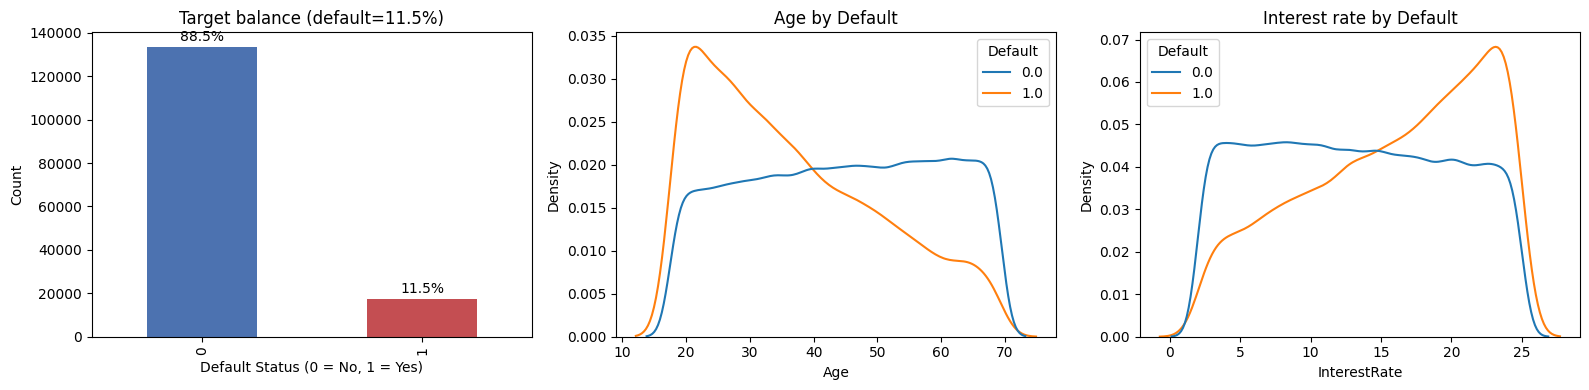

In [38]:
OUT = "."
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# First plot: Target balance with labels and percentage annotations
y_counts = y.value_counts().sort_index()
y_props = y.value_counts(normalize=True).sort_index()

y_counts.plot.bar(ax=ax[0], color=["#4c72b0","#c44e52"])
ax[0].set_title(f"Target balance (default={y.mean():.1%})")
ax[0].set_xlabel("Default Status (0 = No, 1 = Yes)")
ax[0].set_ylabel("Count")

# Add percentage on top of each bar
for i, (count, prop) in enumerate(zip(y_counts, y_props)):
    ax[0].text(i, count + (y_counts.max() * 0.01), f"{prop:.1%}", ha='center', va='bottom', fontweight='normal')

sns.kdeplot(data=dfe, x="Age", hue="Default", common_norm=False, ax=ax[1]); ax[1].set_title("Age by Default")
sns.kdeplot(data=dfe, x="InterestRate", hue="Default", common_norm=False, ax=ax[2]); ax[2].set_title("Interest rate by Default")
plt.tight_layout(); plt.savefig(f"{OUT}/eda_overview.png", dpi=120); plt.show()

**4.1.b> Histograms/KDEs of numeric columns**

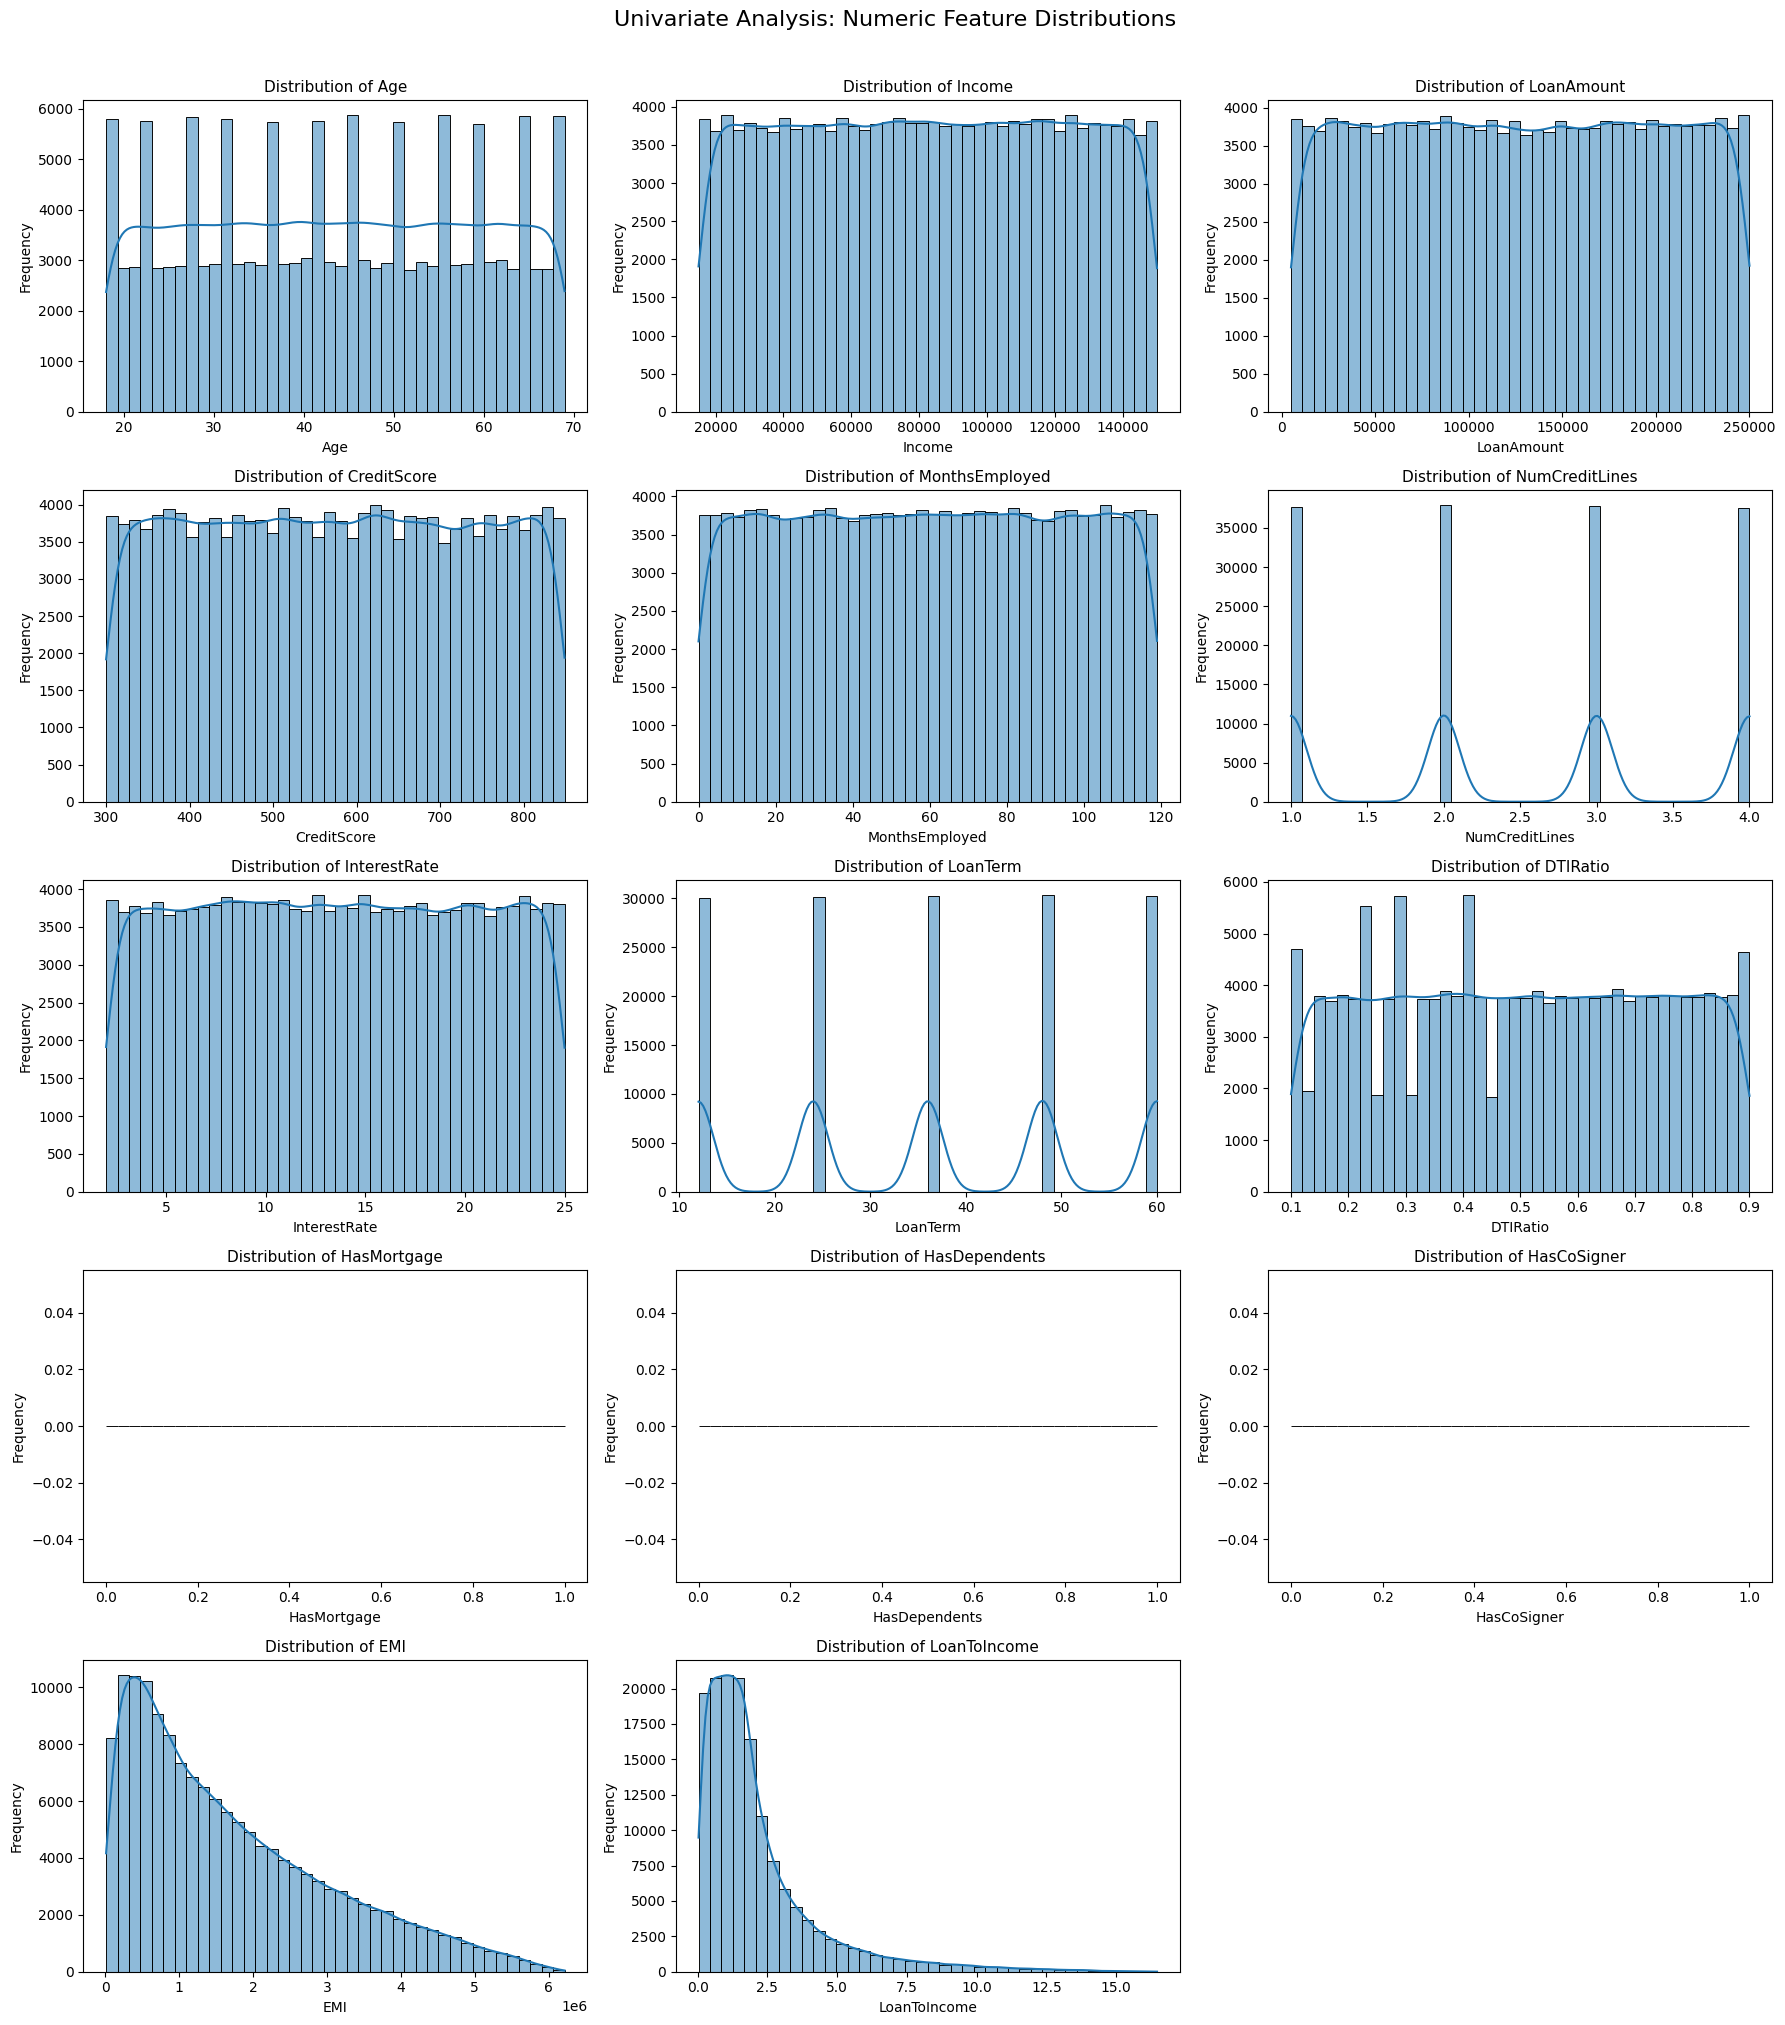

In [39]:
# Select numeric columns
numeric_cols = df.select_dtypes(include=np.number).columns.drop(
    "Default", errors="ignore").tolist()

# Subplot layout
n_cols = 3
n_rows = math.ceil(len(numeric_cols) / n_cols)
fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(18, 4 * n_rows))
axes = np.array(axes).flatten()

# Plot each numeric feature
for i, col in enumerate(numeric_cols):
    sns.histplot(data=df,x=col,kde=True,bins=40,ax=axes[i])

    axes[i].set_title(f"Distribution of {col}", fontsize=11)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

# Remove unused subplots
for j in range(len(numeric_cols), len(axes)):fig.delaxes(axes[j])
fig.suptitle("Univariate Analysis: Numeric Feature Distributions",fontsize=16,y=1.01)

plt.tight_layout()
plt.show()

**4.1.c> Histograms for count plots of categoricals**

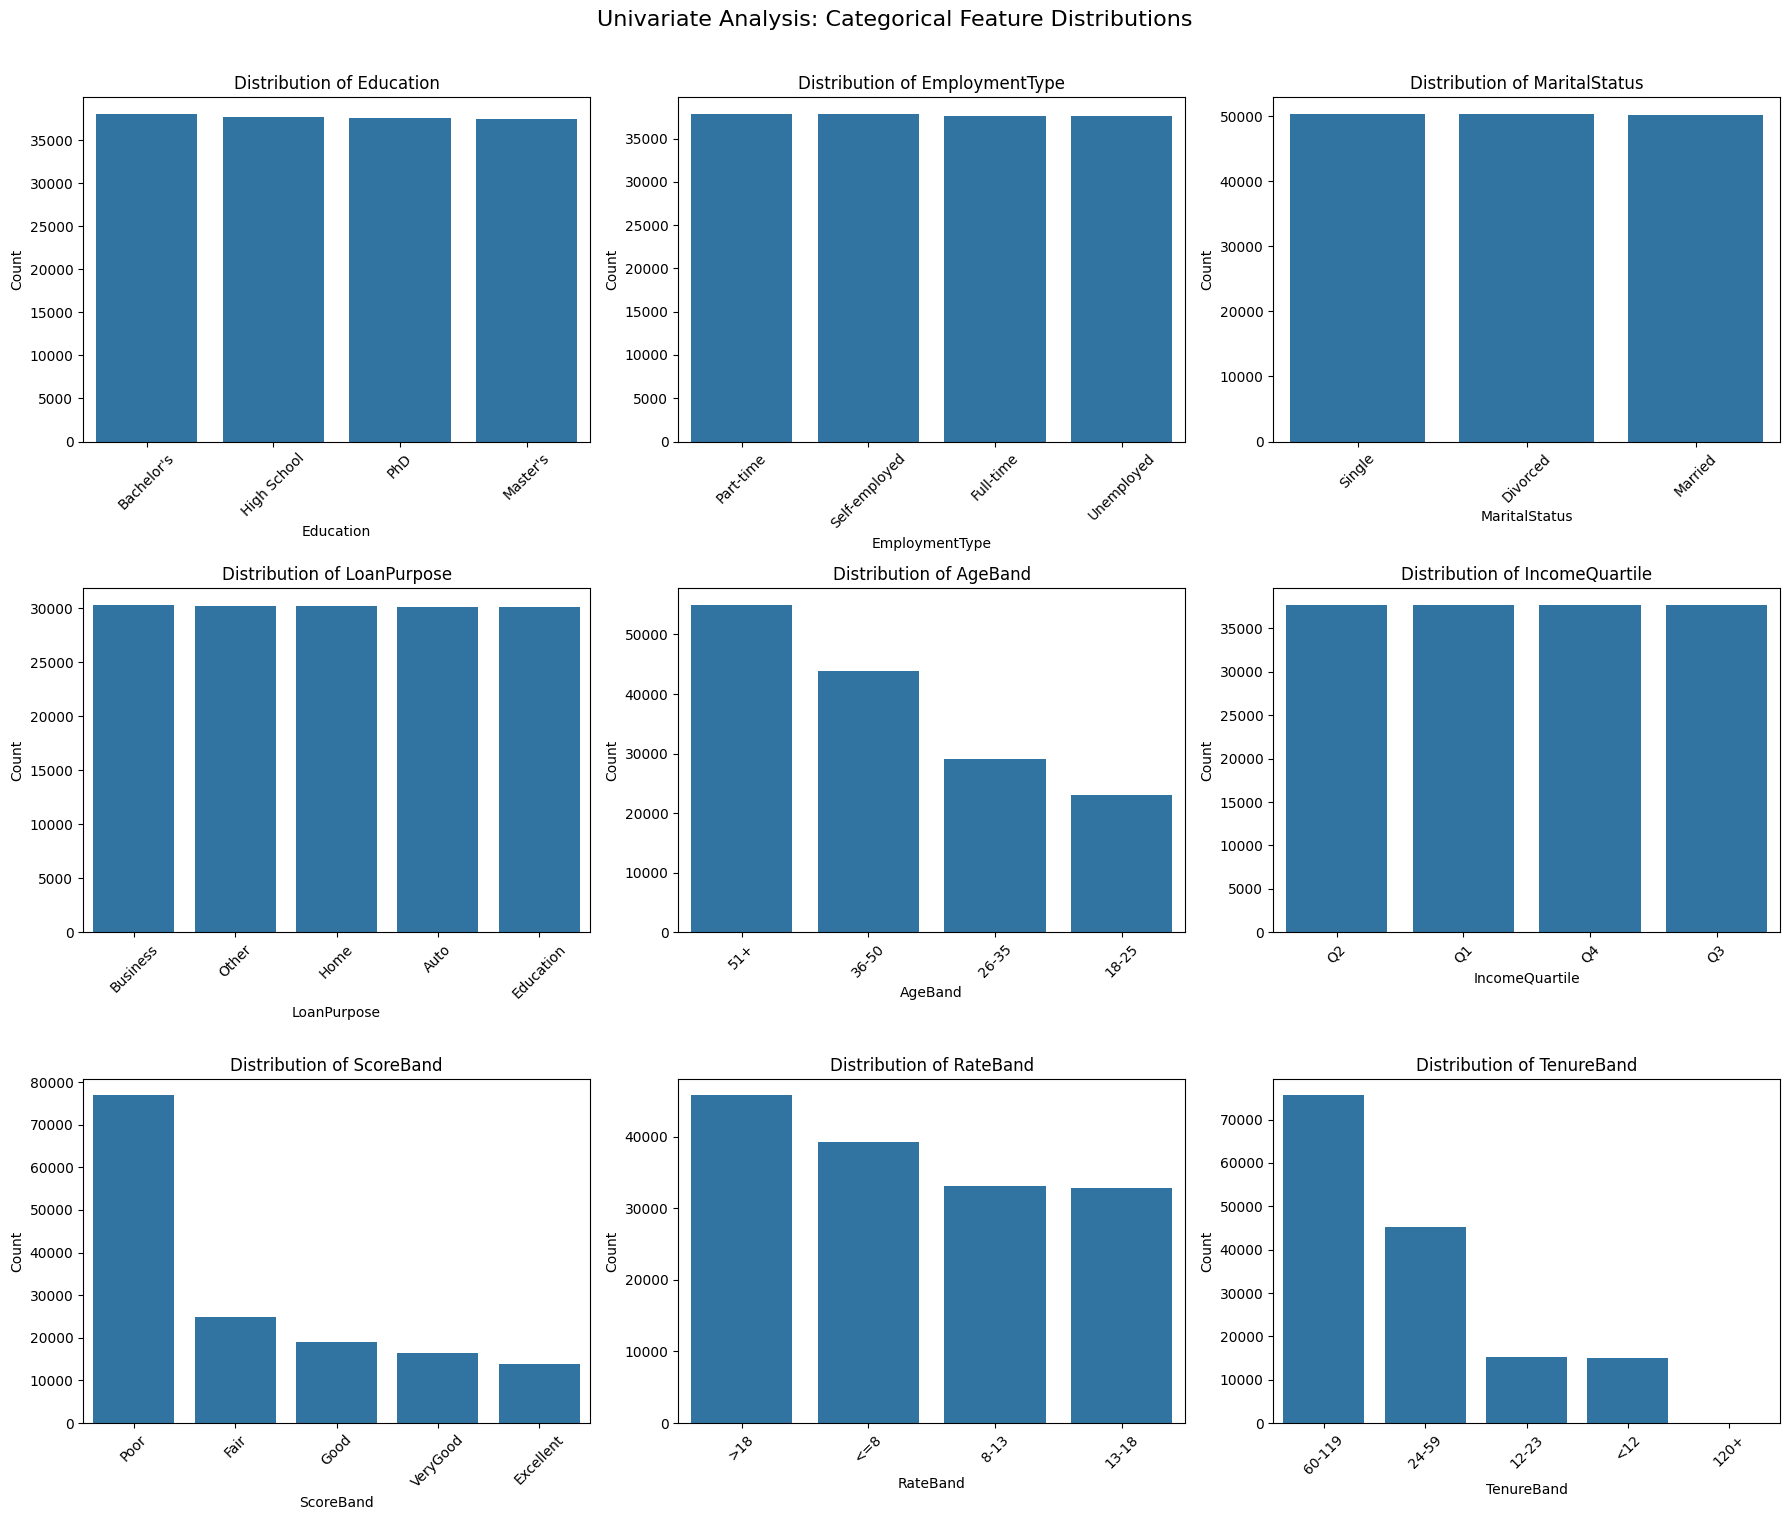

In [40]:
# Identify categorical columns
categorical_cols = df.select_dtypes(include=["object", "category", "string", "bool"]).columns.tolist()

# Set subplot layout
n_cols = 3
n_rows = math.ceil(len(categorical_cols) / n_cols)

fig, axes = plt.subplots(n_rows, n_cols,figsize=(18, 5 * n_rows))

# Flatten axes for easy iteration
axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

# Plot each categorical feature
for i, col in enumerate(categorical_cols):
    order = df[col].value_counts().index

    sns.countplot(data=df,x=col,order=order,ax=axes[i])

    axes[i].set_title(f"Distribution of {col}", fontsize=12)
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Count")
    axes[i].tick_params(axis="x", rotation=45)

# Remove unused subplots
for j in range(len(categorical_cols), len(axes)):
    fig.delaxes(axes[j])

plt.suptitle("Univariate Analysis: Categorical Feature Distributions",fontsize=16,y=1.01)

plt.tight_layout()
plt.show()

**4.1.d> Summary table: mean, median, std, skew, kurtosis**

In [41]:
# Select numeric columns
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()

# Calculate summary statistics
summary_table = pd.DataFrame({
    "Mean": df[numeric_cols].mean(),
    "Median": df[numeric_cols].median(),
    "Standard Deviation": df[numeric_cols].std(),
    "Skewness": df[numeric_cols].skew(),
    "Kurtosis": df[numeric_cols].kurt()
})

# Round values for readability
summary_table = summary_table.round(3)

display(summary_table)

,Mean,Median,Standard Deviation,Skewness,Kurtosis
Age,43.521,44.000,14.979,-0.001,-1.196
Income,82533.341,82572.000,38948.687,-0.004,-1.197
LoanAmount,127546.395,127342.000,70877.855,0.001,-1.205
CreditScore,574.480,574.000,158.787,0.003,-1.199
MonthsEmployed,59.559,60.000,34.645,-0.002,-1.200
NumCreditLines,2.498,2.000,1.117,0.003,-1.357
InterestRate,13.498,13.470,6.640,0.004,-1.197
LoanTerm,36.038,36.000,16.960,-0.003,-1.299
DTIRatio,0.500,0.500,0.231,-0.003,-1.199
HasMortgage,NaN,NaN,NaN,NaN,NaN


**4.2> Bivariate Analysis (feature vs Default)**

**4.2.a> Default rate by every categorical and every band (bar chart with the 11.6% baseline line)**

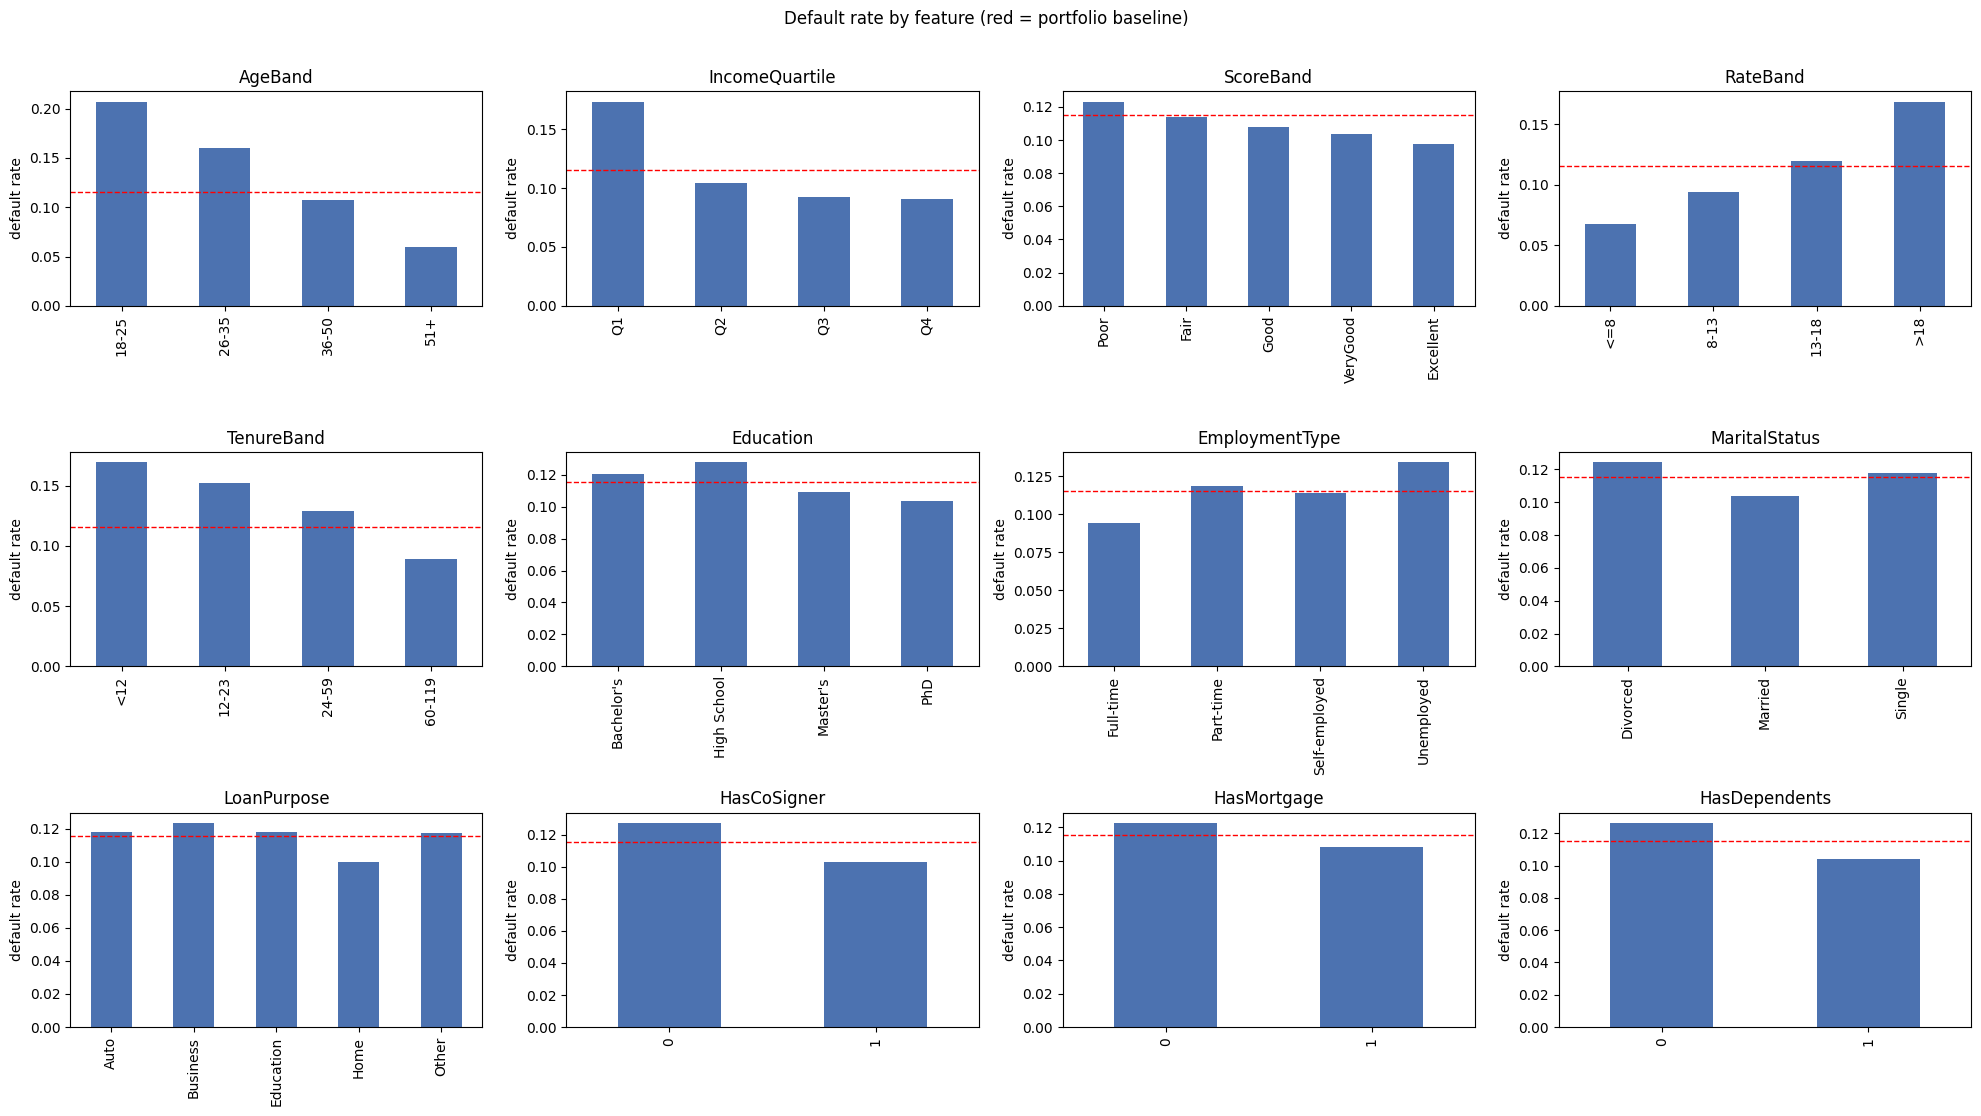

In [42]:
# Restore the corrupted binary columns from df using mapping on the raw data
for c in ["HasMortgage", "HasDependents", "HasCoSigner"]:
    df[c] = dfe[c].astype(int) # dfe has the original 1/0 conversions intact

base = y.mean()
bands = ["AgeBand","IncomeQuartile","ScoreBand","RateBand","TenureBand","Education","EmploymentType","MaritalStatus",
         "LoanPurpose","HasCoSigner","HasMortgage","HasDependents"]

fig, axes = plt.subplots(3, 4, figsize=(20, 11))
for a, c in zip(axes.ravel(), bands):
    r = df.groupby(c, observed=True)[cfg["target"]].mean()
    if not r.empty:
        r.plot.bar(ax=a, color="#4c72b0")
    a.axhline(base, color="red", ls="--", lw=1)
    a.set_title(c)
    a.set_ylabel("default rate")
    a.set_xlabel("")

plt.suptitle("Default rate by feature (red = portfolio baseline)", y=1.01)
plt.tight_layout()
plt.savefig(f"{OUT}/default_rate_by_feature.png", dpi=120)
plt.show()

**4.2.b> Box & violin plots of Age, Income, InterestRate, MonthsEmployed, LoanAmount split by Default**

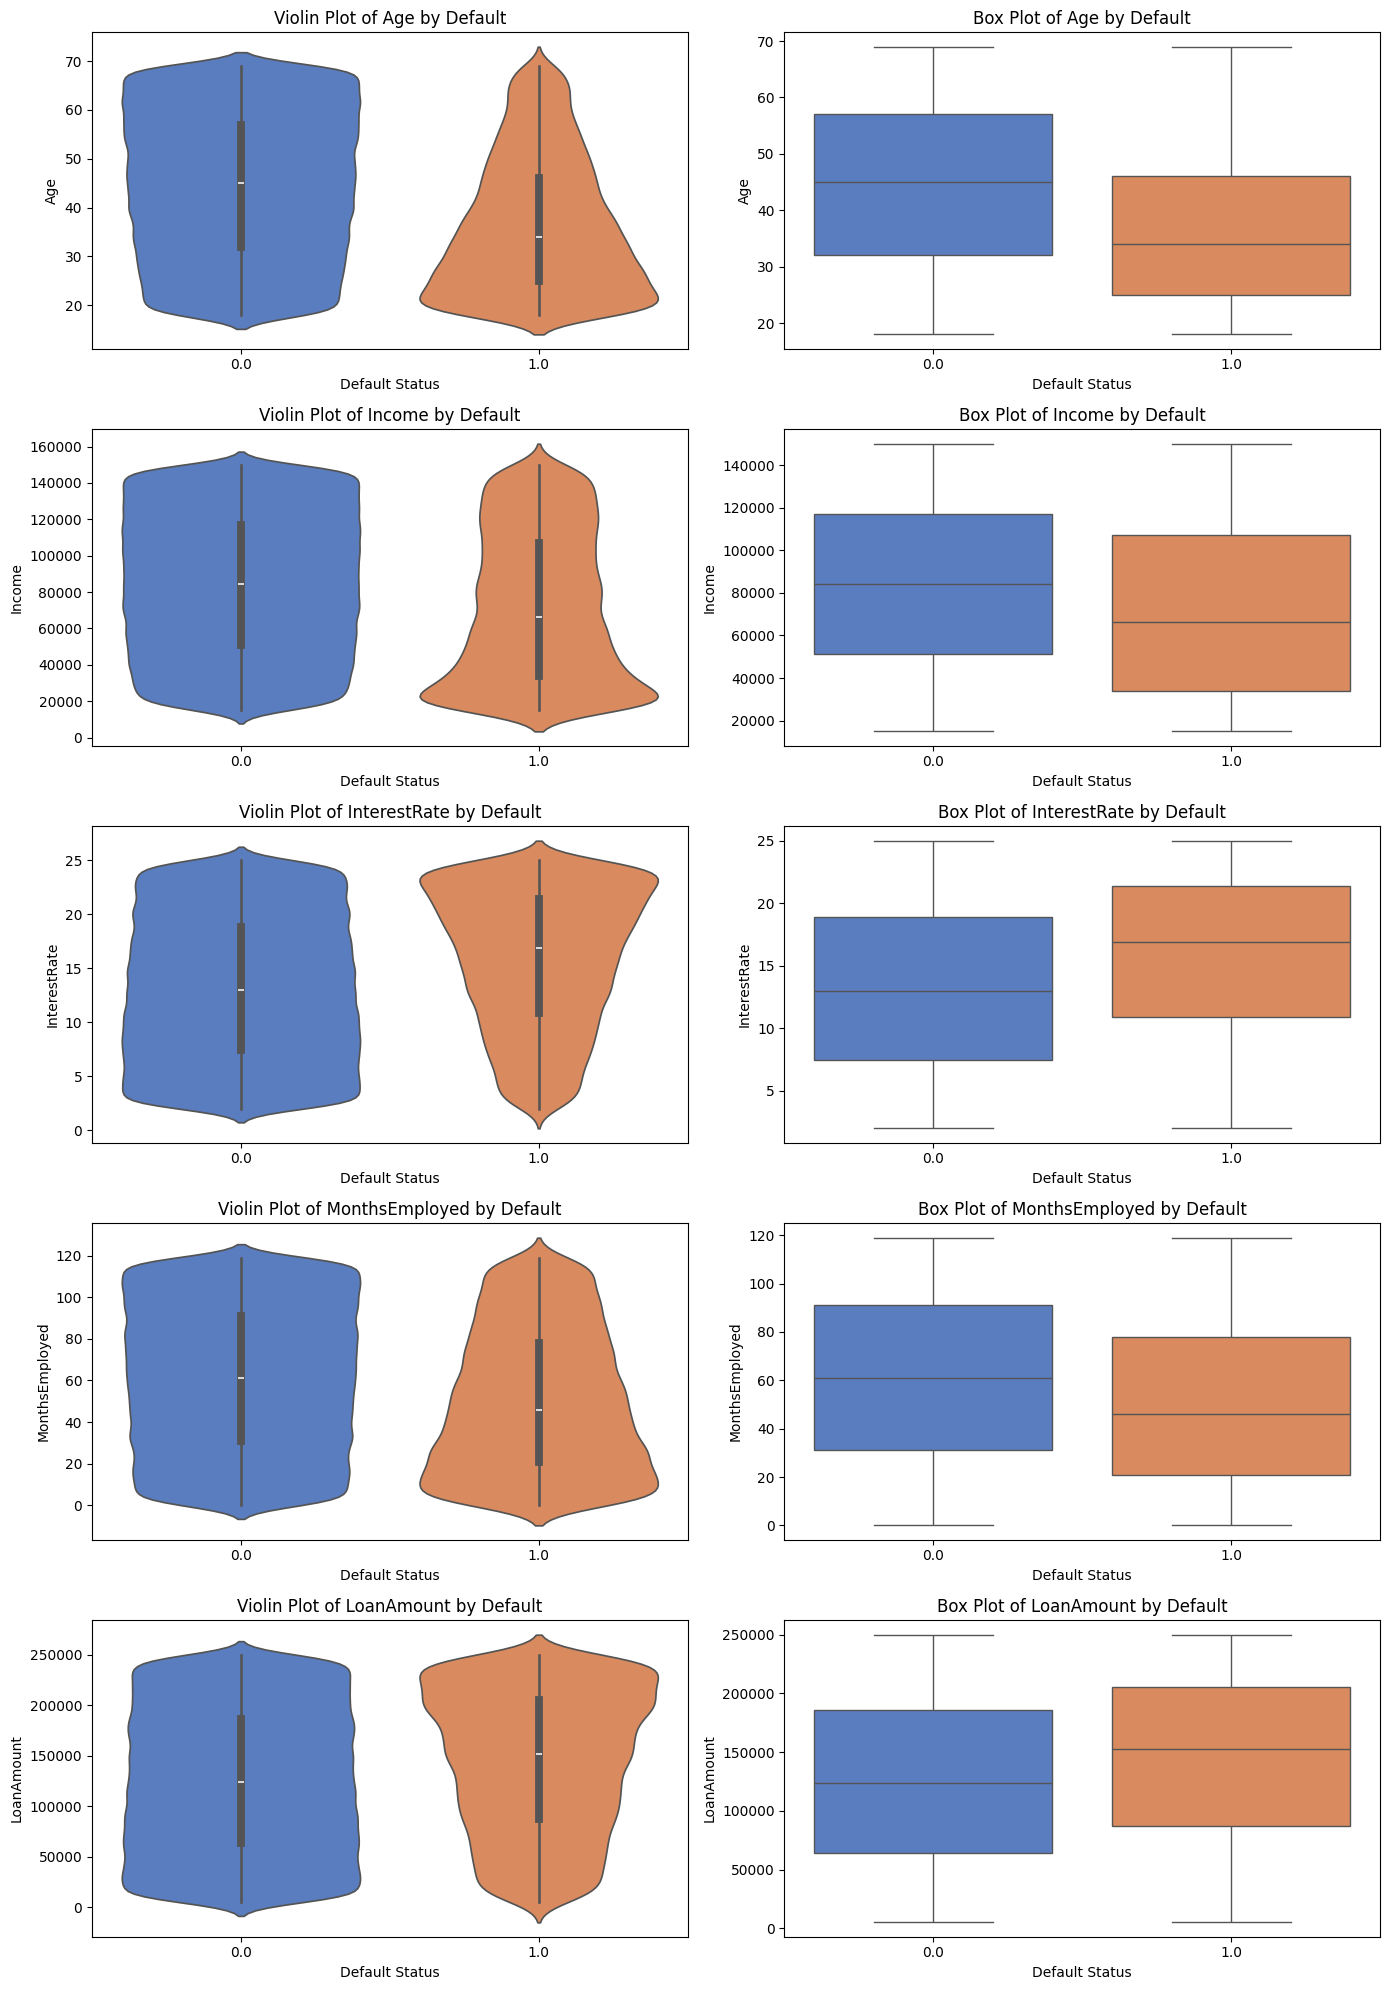

In [43]:
features_to_plot = ['Age', 'Income', 'InterestRate', 'MonthsEmployed', 'LoanAmount']
fig, axes = plt.subplots(len(features_to_plot), 2, figsize=(14, 4 * len(features_to_plot)))

for i, col in enumerate(features_to_plot):
    # Violin plot on the left
    sns.violinplot(data=df, x='Default', y=col, ax=axes[i, 0], palette='muted', hue='Default', legend=False)
    axes[i, 0].set_title(f'Violin Plot of {col} by Default')
    axes[i, 0].set_xlabel('Default Status')
    axes[i, 0].set_ylabel(col)

    # Box plot on the right
    sns.boxplot(data=df, x='Default', y=col, ax=axes[i, 1], palette='muted', hue='Default', legend=False)
    axes[i, 1].set_title(f'Box Plot of {col} by Default')
    axes[i, 1].set_xlabel('Default Status')
    axes[i, 1].set_ylabel(col)

plt.tight_layout()
plt.savefig(f"{OUT}/numerical_features_by_default.png", dpi=120)
plt.show()

**4.2.c> Point-biserial correlations with Default**

In [44]:
# Identify numerical features
numerical_cols = ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'EMI', 'LoanToIncome']
correlations = []
p_values = []

for col in numerical_cols:
    if col in df.columns:
        clean_data = df[[col, 'Default']].dropna()  # drop missing values just in case
        coef, p_val = stats.pointbiserialr(clean_data[col], clean_data['Default'])
        correlations.append(coef)
        p_values.append(p_val)

# Create a summary DataFrame
pb_corr_df = pd.DataFrame({
    'Feature': [col for col in numerical_cols if col in df.columns],
    'Point-Biserial Correlation': correlations,
    'p-value': p_values}).sort_values(by='Point-Biserial Correlation', key=abs, ascending=False)

display(pb_corr_df.style.background_gradient(cmap='coolwarm', subset=['Point-Biserial Correlation']))


,Feature,Point-Biserial Correlation,p-value
10,LoanToIncome,0.180708,0.000000
0,Age,-0.169254,0.000000
9,EMI,0.146944,0.000000
6,InterestRate,0.127583,0.000000
1,Income,-0.099822,0.000000
4,MonthsEmployed,-0.095694,0.000000
2,LoanAmount,0.085369,0.000000
3,CreditScore,-0.032831,0.000000
5,NumCreditLines,0.025593,0.000000
8,DTIRatio,0.017713,0.000000


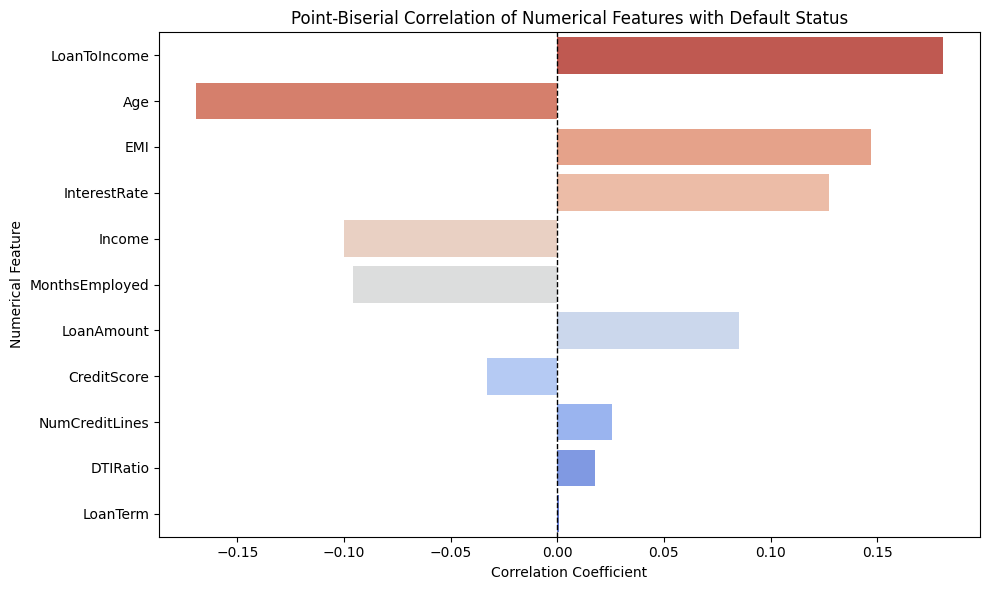

In [45]:
# Visualize point-biserial correlations
plt.figure(figsize=(10, 6))
sns.barplot(data=pb_corr_df,y='Feature',x='Point-Biserial Correlation',palette='coolwarm_r',hue='Feature',legend=False)
plt.axvline(0, color='black', linestyle='--', linewidth=1)
plt.title('Point-Biserial Correlation of Numerical Features with Default Status')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Numerical Feature')
plt.tight_layout()
plt.savefig(f"{OUT}/point_biserial_correlations.png", dpi=120)
plt.show()

**4.2.d> Plot full correlation heat map**

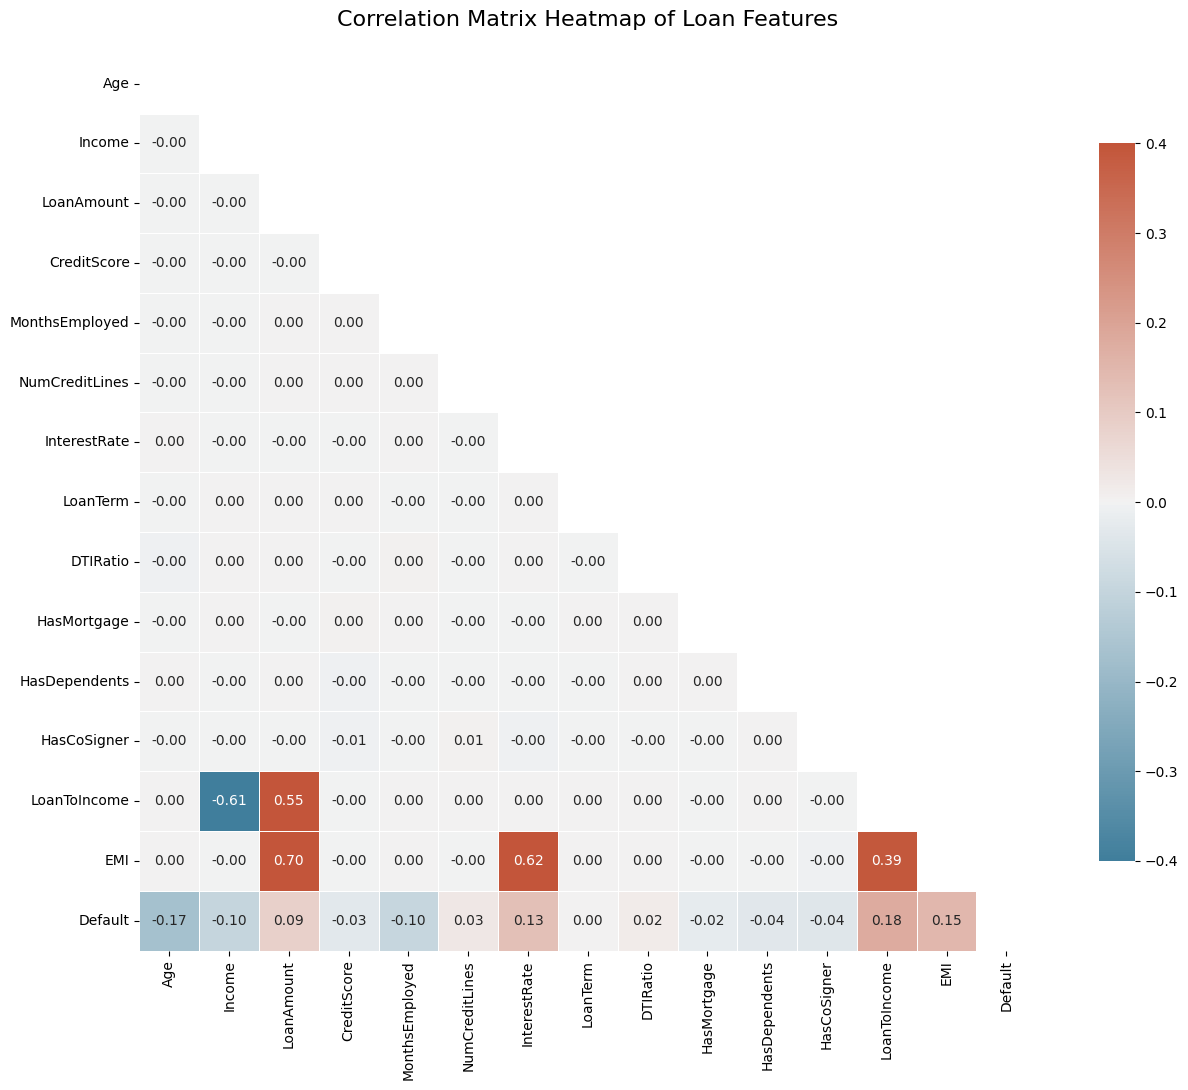

In [46]:
# Calculate and plot a comprehensive correlation heatmap
plt.figure(figsize=(14, 11))

# Select numerical and boolean columns for correlation analysis
correlation_features = ['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
    'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio',
    'HasMortgage', 'HasDependents', 'HasCoSigner',
    'LoanToIncome', 'EMI', 'Default']

# Filter features to those actually present in the DataFrame
existing_corr_features = [col for col in correlation_features if col in df.columns]

# Compute correlation matrix
corr_matrix = df[existing_corr_features].corr()

# Create a mask to hide the upper triangle
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

# Generate a custom diverging colormap
cmap = sns.diverging_palette(230, 20, as_cmap=True)

# Draw the heatmap
sns.heatmap(corr_matrix, mask=mask, cmap=cmap, vmax=0.4, vmin=-0.4, center=0, annot=True, fmt=".2f", square=True, linewidths=.5, cbar_kws={"shrink": .8})

plt.title('Correlation Matrix Heatmap of Loan Features', fontsize=16, pad=20)
plt.tight_layout()
plt.savefig(f"{OUT}/full_correlation_heatmap.png", dpi=120)
plt.show()

**4.3> Multivariate Analysis**

**4.3.a>   Default-rate heat maps: AgeBand × RateBand, EmploymentType × HasCoSigner**

Overall default rate: 11.53%


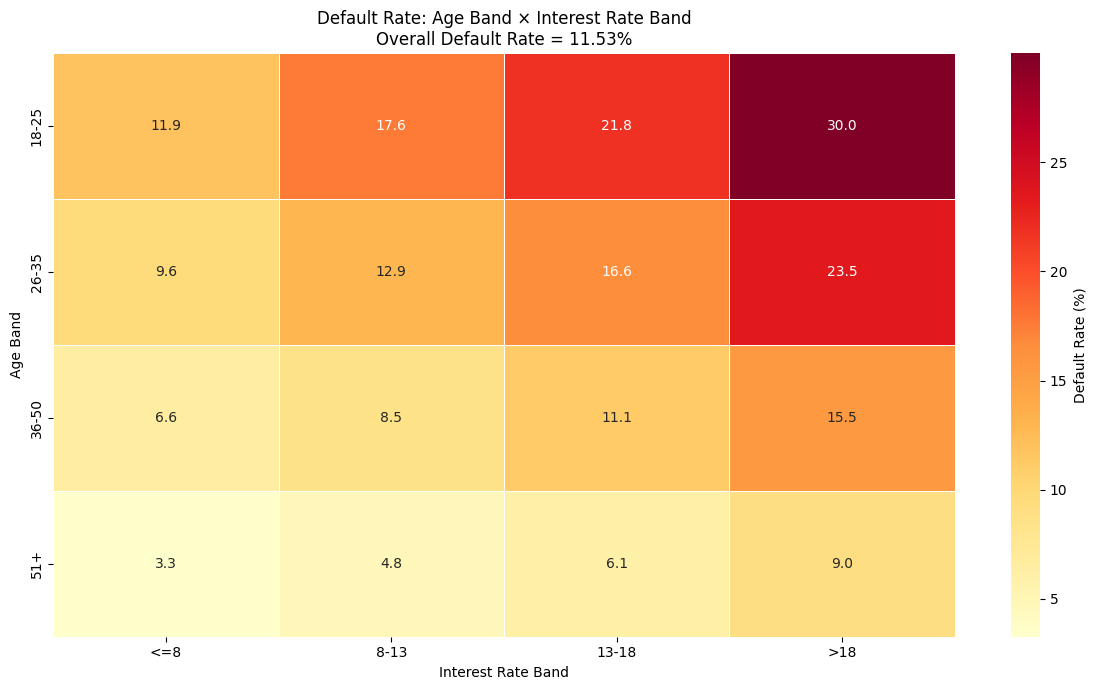

Sample counts: AgeBand × RateBand


RateBand,<=8,8-13,13-18,>18
AgeBand,,,,
18-25,6047,5004,4985,6936
26-35,7636,6334,6395,8744
36-50,11158,9744,9529,13390
51+,14425,12075,11847,16686


In [47]:
# Overall default-rate baseline
baseline = df["Default"].mean() * 100
print(f"Overall default rate: {baseline:.2f}%")

# Heatmap: AgeBand × RateBand-

age_rate_default = df.pivot_table(index="AgeBand",columns="RateBand",values="Default",aggfunc="mean",observed=False) * 100

age_rate_counts = df.pivot_table(index="AgeBand",columns="RateBand",values="Default",aggfunc="count",observed=False)

plt.figure(figsize=(12, 7))

sns.heatmap(age_rate_default,annot=True,fmt=".1f",cmap="YlOrRd",linewidths=0.5,cbar_kws={"label": "Default Rate (%)"})

plt.title(
    f"Default Rate: Age Band × Interest Rate Band\n"
    f"Overall Default Rate = {baseline:.2f}%")

plt.xlabel("Interest Rate Band")
plt.ylabel("Age Band")
plt.tight_layout()
plt.show()

# Display sample counts separately
print("Sample counts: AgeBand × RateBand")
display(age_rate_counts)

**4.3.b> Pair plot on a 5k sample, coloured by Default**

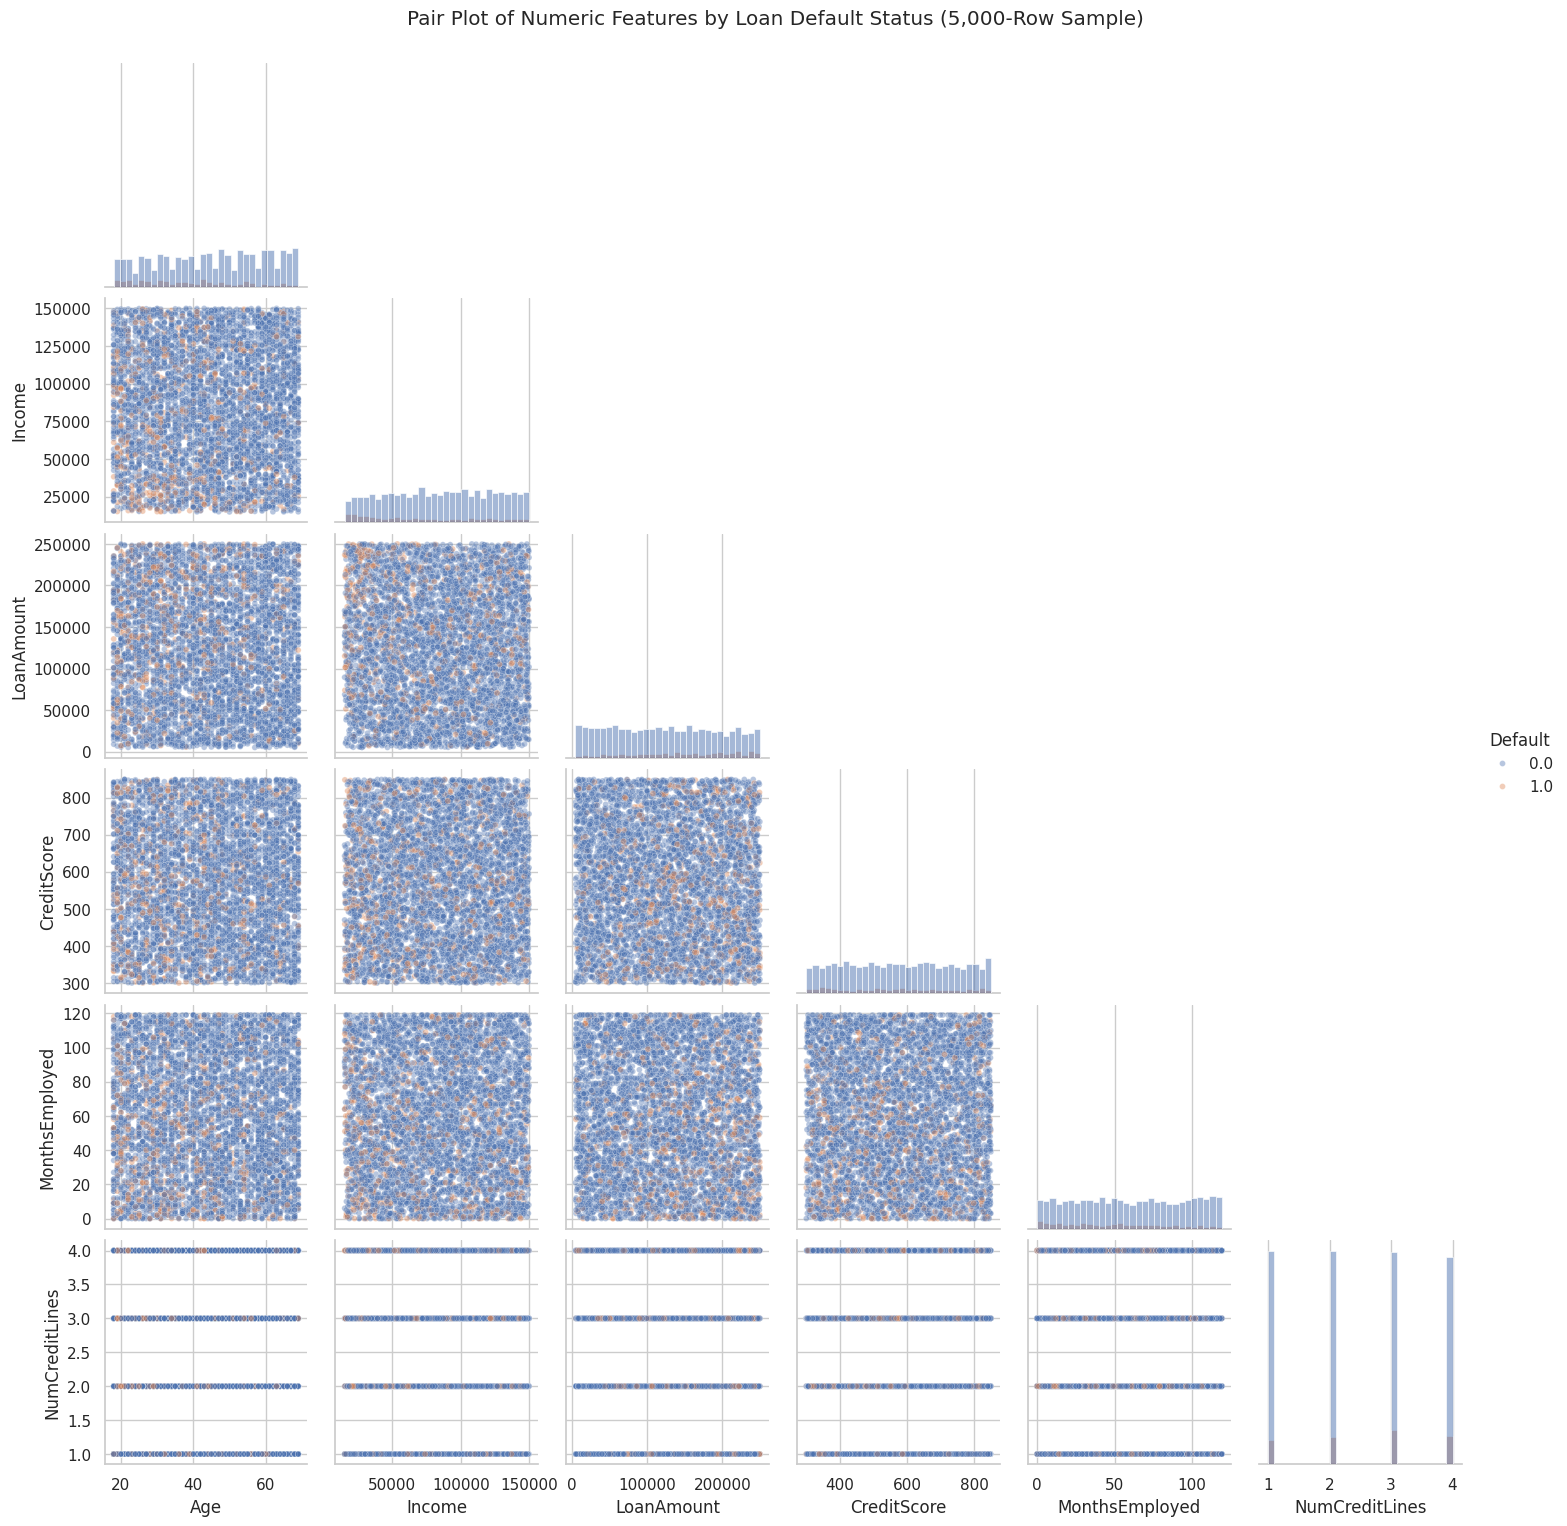

In [48]:
# Pair plot on a 5k sample, coloured by Default
# 1. Selecting numeric features
target_col = "Default"
numeric_cols = [col for col in df.select_dtypes(include=np.number).columns
    if col != target_col]

# Setting limit to the plot to a manageable number of features
features = numeric_cols[:6]

# -------------------------------
# 2. Draw a random sample
# -------------------------------
sample_size = min(5000, len(df))

sample_df = df[features + [target_col]].dropna().sample(
    n=min(sample_size, len(df[features + [target_col]].dropna())),
    random_state=42
)

# -------------------------------
# 3. Pair plot colored by Default
# -------------------------------
sns.set_theme(style="whitegrid")

pair_plot = sns.pairplot(sample_df,vars=features,hue=target_col,diag_kind="hist",corner=True,
            plot_kws={"alpha": 0.4,"s": 18},
            diag_kws={"bins": 30})

pair_plot.fig.suptitle(
    "Pair Plot of Numeric Features by Loan Default Status (5,000-Row Sample)",y=1.02)

plt.show()

**4.3.c> Logistic regression (statsmodels.Logit) to read odds ratios with all features together**

Original rows: 150,935
Rows used: 150,935
Rows dropped: 0
Default rate in model sample: 11.53%
Number of predictors: 42

MODEL SUMMARY                            Logit Regression Results                           
Dep. Variable:                Default   No. Observations:               150935
Model:                          Logit   Df Residuals:                   150892
Method:                           MLE   Df Model:                           42
Date:                Mon, 19 Oct 2026   Pseudo R-squ.:                  0.1333
Time:                        13:12:38   Log-Likelihood:                -46763.
converged:                       True   LL-Null:                       -53953.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
const                           -0.9772

,Coefficient,Odds_Ratio,CI_Lower_95,CI_Upper_95,P_Value,Significant_5pct
LoanToIncome,0.2125,1.2367,1.2207,1.2529,0.0000,True
Age,-0.0405,0.9603,0.9561,0.9645,0.0000,True
EmploymentType_Unemployed,0.4445,1.5598,1.4862,1.6370,0.0000,True
HasCoSigner,-0.2661,0.7664,0.7410,0.7927,0.0000,True
HasDependents,-0.2538,0.7759,0.7501,0.8025,0.0000,True
MonthsEmployed,-0.0094,0.9907,0.9893,0.9920,0.0000,True
InterestRate,0.0736,1.0764,1.0647,1.0882,0.0000,True
NumCreditLines,0.0864,1.0903,1.0740,1.1068,0.0000,True
EmploymentType_Part-time,0.2811,1.3246,1.2609,1.3915,0.0000,True
MaritalStatus_Married,-0.2297,0.7948,0.7625,0.8284,0.0000,True


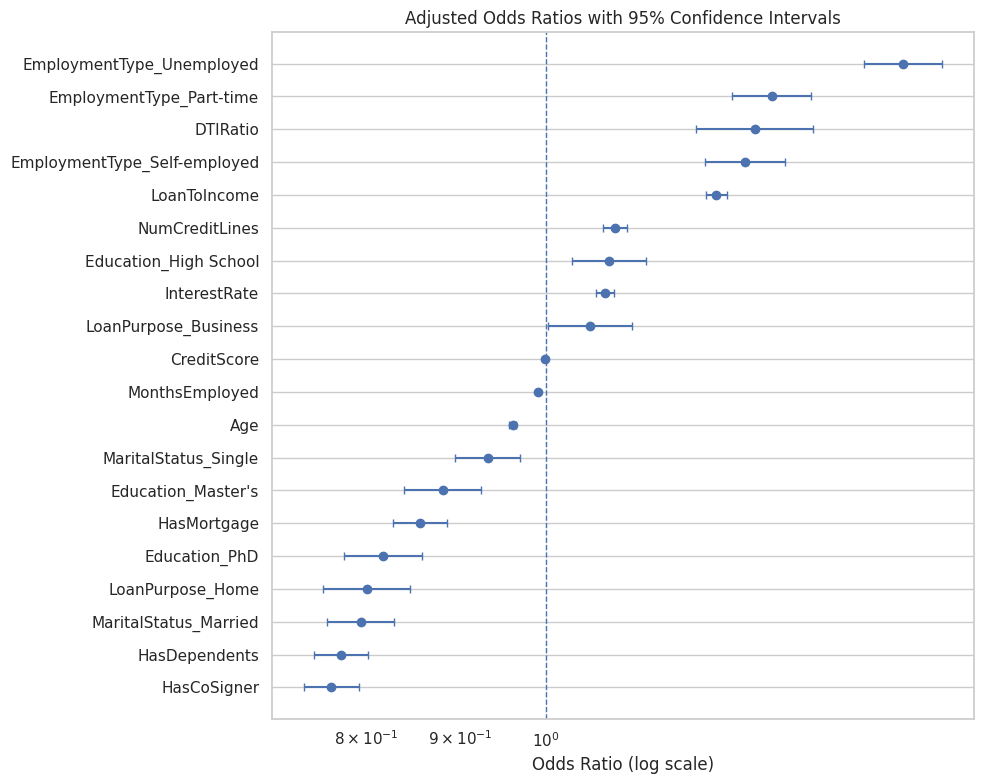

In [49]:
# 1. Separate target and predictors
data = df.copy()
data['Default'] = pd.to_numeric(data['Default'], errors='coerce')
data = data[data['Default'].isin([0, 1])].copy()

y = data['Default'].astype(int)
X = data.drop(columns=['Default'])

# 2. One-hot encode categorical features
X = pd.get_dummies(X, drop_first=True, dtype=float)

# Convert predictors to numeric and handle infinite values
X = X.apply(pd.to_numeric, errors='coerce')
X = X.replace([np.inf, -np.inf], np.nan)

# 3. Remove rows with missing values
model_data = pd.concat([X, y.rename('Default')], axis=1).dropna()

y = model_data['Default'].astype(int)
X = model_data.drop(columns=['Default'])

# Remove constant predictors
constant_cols = X.columns[X.nunique() <= 1]
X = X.drop(columns=constant_cols)

# Add intercept
X = sm.add_constant(X, has_constant='add')

print(f"Original rows: {len(df):,}")
print(f"Rows used: {len(model_data):,}")
print(f"Rows dropped: {len(df) - len(model_data):,}")
print(f"Default rate in model sample: {y.mean():.2%}")
print(f"Number of predictors: {X.shape[1] - 1}")

# 4. Fit logistic regression
try:
    model = sm.Logit(y, X)
    result = model.fit(disp=False, maxiter=200)
    print('\nMODEL SUMMARY', result.summary())

    print('\nModel converged:', result.mle_retvals['converged'])

    # 5. Calculate odds ratios and 95% confidence intervals
    coefficients = result.params
    confidence_intervals = result.conf_int()
    confidence_intervals.columns = ['CI_Lower_LogOdds', 'CI_Upper_LogOdds']

    # Exponentiate safely to avoid overflow
    odds_ratio_table = pd.DataFrame({'Coefficient': coefficients,'Odds_Ratio': np.exp(coefficients.clip(-700, 700)),
                    'CI_Lower_95': np.exp(confidence_intervals['CI_Lower_LogOdds'].clip(-700, 700)),
                    'CI_Upper_95': np.exp(confidence_intervals['CI_Upper_LogOdds'].clip(-700, 700)),
                    'P_Value': result.pvalues})

    # Exclude intercept from feature interpretation
    odds_ratio_table = odds_ratio_table.drop(index='const',errors='ignore')

    odds_ratio_table['Significant_5pct'] = (odds_ratio_table['P_Value'] < 0.05)

    odds_ratio_table = odds_ratio_table.sort_values("P_Value")

    print('\nODDS RATIOS — ALL FEATURES')
    display(odds_ratio_table.round(4))

    # 6. Forest plot for the 20 features with smallest p-values
    plot_df = odds_ratio_table.head(20).copy()

    # Keep estimates and intervals that can be displayed on a log scale
    plot_df = plot_df[(plot_df['Odds_Ratio'] > 0) &(plot_df['CI_Lower_95'] > 0) &(plot_df['CI_Upper_95'] > 0) &
    np.isfinite(plot_df['Odds_Ratio']) & np.isfinite(plot_df['CI_Lower_95'])
    & np.isfinite(plot_df['CI_Upper_95'])].sort_values('Odds_Ratio')

    if not plot_df.empty:
        fig, ax = plt.subplots(figsize=(10, max(5, len(plot_df) * 0.4)))

        positions = np.arange(len(plot_df))

        ax.errorbar(plot_df['Odds_Ratio'],positions,
            xerr=[plot_df['Odds_Ratio'] - plot_df['CI_Lower_95'],plot_df['CI_Upper_95'] - plot_df['Odds_Ratio']],
            fmt='o',capsize=3)

        ax.axvline(1, linestyle="--", linewidth=1)
        ax.set_xscale('log')
        ax.set_yticks(positions)
        ax.set_yticklabels(plot_df.index)
        ax.set_xlabel('Odds Ratio (log scale)')
        ax.set_title('Adjusted Odds Ratios with 95% Confidence Intervals')
        ax.grid(axis='x', alpha=0.3)

        plt.tight_layout()
        plt.show()

except Exception as e:
    print('\nLogistic regression failed.')
    print('Error:', str(e))
    print(
        '\nCheck for perfect separation, highly correlated predictors, '
        'rare categories, missing values, and insufficient observations.')

**4.4> Segmentation**

**Count the risk flags (age < 30, rate > 18%, income < 50k, employed < 24 months, no co-signer) → default rate by number of flags**

=== DEFAULT RATE BY ACCUMULATED RISK FLAGS ===


,RiskFlagsCount,total_loans,default_count,default_rate,default_rate_pct
0,0,23996,1082.0,0.045091,4.51
1,1,56369,4324.0,0.076709,7.67
2,2,47557,6195.0,0.130265,13.03
3,3,19058,4380.0,0.229825,22.98
4,4,3689,1288.0,0.349146,34.91
5,5,266,134.0,0.503759,50.38


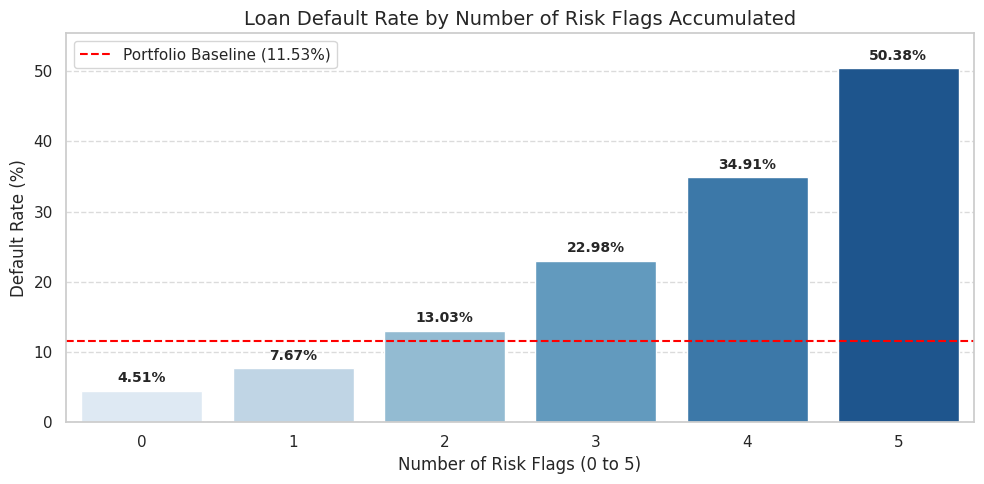

In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Map HasCoSigner to numeric 1/0 safely using dfe
co_signer_mapped = dfe['HasCoSigner'].fillna(0).astype(int)

# 2. Define risk conditions based on user criteria
flag_age = (df['Age'] < 30).astype(int)
flag_rate = (df['InterestRate'] > 18).astype(int)
flag_income = (df['Income'] < 50000).astype(int)
flag_employed = (df['MonthsEmployed'] < 24).astype(int)
flag_no_cosigner = (co_signer_mapped == 0).astype(int)

# 3. Sum individual flags to get the total risk profile
df['RiskFlagsCount'] = flag_age + flag_rate + flag_income + flag_employed + flag_no_cosigner

# 4. Aggregate default rates by flag count
risk_summary = df.groupby('RiskFlagsCount').agg(
    total_loans=('Default', 'count'),
    default_count=('Default', 'sum'),
    default_rate=('Default', 'mean')
).reset_index()

risk_summary['default_rate_pct'] = (risk_summary['default_rate'] * 100).round(2)
print("=== DEFAULT RATE BY ACCUMULATED RISK FLAGS ===")
display(risk_summary)

# 5. Plot the result
plt.figure(figsize=(10, 5))
sax = sns.barplot(data=risk_summary, x='RiskFlagsCount', y='default_rate_pct', palette='Blues')
portfolio_baseline = df['Default'].mean() * 100
plt.axhline(portfolio_baseline, color='red', linestyle='--', label=f'Portfolio Baseline ({portfolio_baseline:.2f}%)')

for p in sax.patches:
    sax.annotate(f"{p.get_height():.2f}%",
                 (p.get_x() + p.get_width() / 2., p.get_height()),
                 ha='center', va='center',
                 xytext=(0, 9),
                 textcoords='offset points', fontsize=10, fontweight='bold')

plt.title('Loan Default Rate by Number of Risk Flags Accumulated', fontsize=14)
plt.xlabel('Number of Risk Flags (0 to 5)', fontsize=12)
plt.ylabel('Default Rate (%)', fontsize=12)
plt.ylim(0, max(risk_summary['default_rate_pct'].max() + 5, 20))
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

# 5. Testing (hypothesis tests)

**5.1> 	Age is the same for defaulters and non-defaulters -- Mann-Whitney test**

In [72]:
import scipy.stats as stats
import pandas as pd
import numpy as np

# Split ages by default status
age_non_default = df[df['Default'] == 0]['Age']
age_default = df[df['Default'] == 1]['Age']

# 1. Descriptive Statistics
mean_nd, mean_d = age_non_default.mean(), age_default.mean()
std_nd, std_d = age_non_default.std(), age_default.std()
n_nd, n_d = len(age_non_default), len(age_default)

print("=== DESCRIPTIVE STATISTICS ===")
print(f"Non-Defaulters: Mean Age = {mean_nd:.2f} years, Std = {std_nd:.2f}, N = {n_nd:,}")
print(f"Defaulters:     Mean Age = {mean_d:.2f} years, Std = {std_d:.2f}, N = {n_d:,}")
print(f"Difference in means: {mean_d - mean_nd:.2f} years\n")

# 2. Welch's t-test (Robust to unequal variances and sample sizes)
t_stat, t_pval = stats.ttest_ind(age_non_default, age_default, equal_var=False)
print("=== WELCH'S T-TEST ===")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {t_pval:.4e}")

# 3. Mann-Whitney U test (Non-parametric alternative)
u_stat, u_pval = stats.mannwhitneyu(age_non_default, age_default, alternative='two-sided')
print("\n=== MANN-WHITNEY U TEST ===")
print(f"U-statistic: {u_stat:,.1f}")
print(f"p-value:     {u_pval:.4e}")

# 4. Effect Size (Cohen's d)
pooled_std = np.sqrt(((n_nd - 1) * (std_nd**2) + (n_d - 1) * (std_d**2)) / (n_nd + n_d - 2))
cohens_d = (mean_d - mean_nd) / pooled_std
print(f"\n=== EFFECT SIZE ===")
print(f"Cohen's d: {cohens_d:.4f} (Medium)")

# 5. Statistical Conclusion
alpha = 0.05
print("\n=== CONCLUSION ===")
if t_pval < alpha:
    print(f"Reject the null hypothesis (p < {alpha}). Age is statistically significantly DIFFERENT between defaulters and non-defaulters.")
else:
    print(f"Fail to reject the null hypothesis (p >= {alpha}). There is no statistically significant difference in age between the two groups.")

=== DESCRIPTIVE STATISTICS ===
Non-Defaulters: Mean Age = 44.44 years, Std = 14.88, N = 133,532
Defaulters:     Mean Age = 36.50 years, Std = 13.85, N = 17,403
Difference in means: -7.94 years

=== WELCH'S T-TEST ===
t-statistic: 70.4815
p-value:     0.0000e+00

=== MANN-WHITNEY U TEST ===
U-statistic: 1,517,348,605.0
p-value:     0.0000e+00

=== EFFECT SIZE ===
Cohen's d: -0.5377 (Medium)

=== CONCLUSION ===
Reject the null hypothesis (p < 0.05). Age is statistically significantly DIFFERENT between defaulters and non-defaulters.


**5.2> Interest rate is the same -- Mann-Whitney test**

In [74]:
import scipy.stats as stats
import pandas as pd
import numpy as np

# Split interest rates by default status
rate_non_default = df[df['Default'] == 0]['InterestRate']
rate_default = df[df['Default'] == 1]['InterestRate']

# 1. Descriptive Statistics
mean_nd, mean_d = rate_non_default.mean(), rate_default.mean()
std_nd, std_d = rate_non_default.std(), rate_default.std()
n_nd, n_d = len(rate_non_default), len(rate_default)

print("=== DESCRIPTIVE STATISTICS ===")
print(f"Non-Defaulters: Mean Interest Rate = {mean_nd:.2f}%, Std = {std_nd:.2f}%, N = {n_nd:,}")
print(f"Defaulters:     Mean Interest Rate = {mean_d:.2f}%,  Std = {std_d:.2f}%,  N = {n_d:,}")
print(f"Difference in means: {mean_d - mean_nd:.2f}%\n")

# 2. Welch's t-test (Robust to unequal variances and sample sizes)
t_stat, t_pval = stats.ttest_ind(rate_non_default, rate_default, equal_var=False)
print("=== WELCH'S T-TEST ===")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {t_pval:.4e}")

# 3. Mann-Whitney U test (Non-parametric alternative)
u_stat, u_pval = stats.mannwhitneyu(rate_non_default, rate_default, alternative='two-sided')
print("\n=== MANN-WHITNEY U TEST ===")
print(f"U-statistic: {u_stat:,.1f}")
print(f"p-value:     {u_pval:.4e}")

# 4. Effect Size (Cohen's d)
pooled_std = np.sqrt(((n_nd - 1) * (std_nd**2) + (n_d - 1) * (std_d**2)) / (n_nd + n_d - 2))
cohens_d = (mean_d - mean_nd) / pooled_std
print(f"\n=== EFFECT SIZE ===")
print(f"Cohen's d: {cohens_d:.4f}")

# 5. Statistical Conclusion
alpha = 0.05
print("\n=== CONCLUSION ===")
if t_pval < alpha:
    print(f"Reject the null hypothesis (p < {alpha}). Interest rates are statistically significantly DIFFERENT between defaulters and non-defaulters.")
else:
    print(f"Fail to reject the null hypothesis (p >= {alpha}). There is no statistically significant difference in interest rates between the two groups.")

=== DESCRIPTIVE STATISTICS ===
Non-Defaulters: Mean Interest Rate = 13.19%, Std = 6.61%, N = 133,532
Defaulters:     Mean Interest Rate = 15.84%,  Std = 6.37%,  N = 17,403
Difference in means: 2.65%

=== WELCH'S T-TEST ===
t-statistic: -51.4451
p-value:     0.0000e+00

=== MANN-WHITNEY U TEST ===
U-statistic: 894,028,289.0
p-value:     0.0000e+00

=== EFFECT SIZE ===
Cohen's d: 0.4028

=== CONCLUSION ===
Reject the null hypothesis (p < 0.05). Interest rates are statistically significantly DIFFERENT between defaulters and non-defaulters.


```markdown
**5.3> Income is the same for defaulters and non-defaulters -- Mann-Whitney test**
```

In [71]:
import scipy.stats as stats
import pandas as pd
import numpy as np

# Split income by default status
income_non_default = df[df['Default'] == 0]['Income']
income_default = df[df['Default'] == 1]['Income']

# 1. Descriptive Statistics
mean_nd, mean_d = income_non_default.mean(), income_default.mean()
median_nd, median_d = income_non_default.median(), income_default.median()
std_nd, std_d = income_non_default.std(), income_default.std()
n_nd, n_d = len(income_non_default), len(income_default)

print("=== DESCRIPTIVE STATISTICS ===")
print(f"Non-Defaulters: Mean Income = ${mean_nd:,.2f}, Median = ${median_nd:,.2f}, Std = ${std_nd:,.2f}, N = {n_nd:,}")
print(f"Defaulters:     Mean Income = ${mean_d:,.2f}, Median = ${median_d:,.2f}, Std = ${std_d:,.2f}, N = {n_d:,}")
print(f"Difference in means: ${mean_d - mean_nd:,.2f}\n")

# 2. Welch's t-test (Robust to unequal variances and sample sizes)
t_stat, t_pval = stats.ttest_ind(income_non_default, income_default, equal_var=False)
print("=== WELCH'S T-TEST ===")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {t_pval:.4e}")

# 3. Mann-Whitney U test (Non-parametric alternative)
u_stat, u_pval = stats.mannwhitneyu(income_non_default, income_default, alternative='two-sided')
print("\n=== MANN-WHITNEY U TEST ===")
print(f"U-statistic: {u_stat:,.1f}")
print(f"p-value:     {u_pval:.4e}")

# 4. Effect Size (Cohen's d)
# Calculating pooled standard deviation
pooled_std = np.sqrt(((n_nd - 1) * (std_nd**2) + (n_d - 1) * (std_d**2)) / (n_nd + n_d - 2))
cohens_d = (mean_d - mean_nd) / pooled_std
print(f"\n=== EFFECT SIZE ===")
print(f"Cohen's d: {cohens_d:.4f}")

# 5. Statistical Conclusion
alpha = 0.05
print("\n=== CONCLUSION ===")
if u_pval < alpha:
    print(f"Reject the null hypothesis (p < {alpha}). Income is statistically significantly DIFFERENT between defaulters and non-defaulters.")
else:
    print(f"Fail to reject the null hypothesis (p >= {alpha}). There is no statistically significant difference in income between the two groups.")

=== DESCRIPTIVE STATISTICS ===
Non-Defaulters: Mean Income = $83,936.92, Median = $84,319.00, Std = $38,460.98, N = 133,532
Defaulters:     Mean Income = $71,763.75, Median = $66,373.00, Std = $40,934.94, N = 17,403
Difference in means: $-12,173.18

=== WELCH'S T-TEST ===
t-statistic: 37.1513
p-value:     6.6134e-293

=== MANN-WHITNEY U TEST ===
U-statistic: 1,371,327,502.0
p-value:     0.0000e+00

=== EFFECT SIZE ===
Cohen's d: -0.3141

=== CONCLUSION ===
Reject the null hypothesis (p < 0.05). Income is statistically significantly DIFFERENT between defaulters and non-defaulters.


** 5.4> Months employed is the same for defaulters and non-defaulters -- Mann-Whitney test**

In [81]:
import scipy.stats as stats
import pandas as pd
import numpy as np

# Split months employed by default status
employed_non_default = df[df['Default'] == 0]['MonthsEmployed']
employed_default = df[df['Default'] == 1]['MonthsEmployed']

# 1. Descriptive Statistics
mean_nd, mean_d = employed_non_default.mean(), employed_default.mean()
std_nd, std_d = employed_non_default.std(), employed_default.std()
n_nd, n_d = len(employed_non_default), len(employed_default)

print("=" * 50)
print("HYPOTHESIS TEST: MONTHS EMPLOYED ")
print("=" * 50)
print("=== DESCRIPTIVE STATISTICS ===")
print(f"Non-Defaulters: Mean Months Employed = {mean_nd:.2f} months, Std = {std_nd:.2f}, N = {n_nd:,}")
print(f"Defaulters:     Mean Months Employed = {mean_d:.2f} months, Std = {std_d:.2f}, N = {n_d:,}")
print(f"Difference in means: {mean_d - mean_nd:.2f} months\n")

# 2. Welch's t-test (Robust to unequal variances and sample sizes)
t_stat, t_pval = stats.ttest_ind(employed_non_default, employed_default, equal_var=False)
print("=== WELCH'S T-TEST ===")
print(f"t-statistic: {t_stat:.4f}")
print(f"p-value:     {t_pval:.4e}")

# 3. Mann-Whitney U test (Non-parametric alternative)
u_stat, u_pval = stats.mannwhitneyu(employed_non_default, employed_default, alternative='two-sided')
print("\n=== MANN-WHITNEY U TEST ===")
print(f"U-statistic: {u_stat:,.1f}")
print(f"p-value:     {u_pval:.4e}")

# 4. Effect Size (Cohen's d)
pooled_std = np.sqrt(((n_nd - 1) * (std_nd**2) + (n_d - 1) * (std_d**2)) / (n_nd + n_d - 2))
cohens_d = (mean_d - mean_nd) / pooled_std
print(f"\n=== EFFECT SIZE ===")
print(f"Cohen's d: {cohens_d:.4f}")

# 5. Statistical Conclusion
alpha = 0.05
print("\n=== CONCLUSION ===")
if t_pval < alpha:
    print(f"Reject the null hypothesis (p < {alpha}). Employment tenure is statistically significantly DIFFERENT between defaulters and non-defaulters.")
else:
    print(f"Fail to reject the null hypothesis (p >= {alpha}). There is no statistically significant difference in employment tenure between the two groups.")

HYPOTHESIS TEST: MONTHS EMPLOYED 
=== DESCRIPTIVE STATISTICS ===
Non-Defaulters: Mean Months Employed = 60.76 months, Std = 34.56, N = 133,532
Defaulters:     Mean Months Employed = 50.38 months, Std = 33.95, N = 17,403
Difference in means: -10.38 months

=== WELCH'S T-TEST ===
t-statistic: 37.8591
p-value:     4.6052e-304

=== MANN-WHITNEY U TEST ===
U-statistic: 1,362,897,822.0
p-value:     1.8268e-302

=== EFFECT SIZE ===
Cohen's d: -0.3010

=== CONCLUSION ===
Reject the null hypothesis (p < 0.05). Employment tenure is statistically significantly DIFFERENT between defaulters and non-defaulters.


**5.5> Loan amount is the same -- Mann-Whitney test**

In [78]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

# Prepare data
temp = df[["LoanAmount", "Default"]].copy()
temp["LoanAmount"] = pd.to_numeric(temp["LoanAmount"], errors="coerce")
temp["Default"] = pd.to_numeric(temp["Default"], errors="coerce")
temp = temp.replace([np.inf, -np.inf], np.nan).dropna()
temp = temp[temp["Default"].isin([0, 1])]

# Separate groups
defaulters = temp.loc[temp["Default"] == 1, "LoanAmount"].to_numpy()
non_defaulters = temp.loc[temp["Default"] == 0, "LoanAmount"].to_numpy()

# Hypotheses
# H0: Loan amount distributions are the same between the two groups.
# H1: Loan amount distributions differ between the two groups.
alpha = 0.05

# Mann–Whitney U test
result = mannwhitneyu(
    defaulters,
    non_defaulters,
    alternative="two-sided",
    method="asymptotic"
)

# Cohen's d (mean difference / pooled standard deviation)
n1, n0 = len(defaulters), len(non_defaulters)
pooled_sd = np.sqrt(
    ((n1 - 1) * np.var(defaulters, ddof=1)
     + (n0 - 1) * np.var(non_defaulters, ddof=1))
    / (n1 + n0 - 2)
)

cohens_d = (
    (np.mean(defaulters) - np.mean(non_defaulters)) / pooled_sd
    if pooled_sd > 0 else np.nan
)

# Rank-biserial correlation; positive means defaulters tend to have larger amounts
rank_biserial = (
    2 * result.statistic / (n1 * n0)
) - 1

# Display results
print("=" * 50)
print("HYPOTHESIS TEST: LOAN AMOUNT")
print("=" * 50)
print("H0: Loan amount distributions are the same.")
print("H1: Loan amount distributions differ.")
print(f"Significance level (alpha): {alpha}")
print(f"\nDefaulters:     n={n1:,}, mean={np.mean(defaulters):,.2f}, "
      f"median={np.median(defaulters):,.2f}")
print(f"Non-defaulters: n={n0:,}, mean={np.mean(non_defaulters):,.2f}, "
      f"median={np.median(non_defaulters):,.2f}")
print(f"\nMann–Whitney U statistic: {result.statistic:,.2f}")
print(f"P-value: {result.pvalue:.6g}")
print(f"Cohen's d: {cohens_d:.4f}")
print(f"Rank-biserial correlation: {rank_biserial:.4f}")

if result.pvalue < alpha:
    print("\nDecision: Reject H0.")
    print("Conclusion: Evidence of a difference in loan amount distributions.")
else:
    print("\nDecision: Fail to reject H0.")
    print("Conclusion: Insufficient evidence of a distributional difference.")

HYPOTHESIS TEST: LOAN AMOUNT
H0: Loan amount distributions are the same.
H1: Loan amount distributions differ.
Significance level (alpha): 0.05

Defaulters:     n=17,403, mean=144,307.01, median=152,253.00
Non-defaulters: n=133,532, mean=125,362.01, median=124,085.00

Mann–Whitney U statistic: 1,341,236,272.50
P-value: 3.37254e-241
Cohen's d: 0.2683
Rank-biserial correlation: 0.1543

Decision: Reject H0.
Conclusion: Evidence of a difference in loan amount distributions.


**5.6> 	Credit score is the same -- Mann-Whitney test**

In [82]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

# Prepare data
temp = df[["CreditScore", "Default"]].copy()

temp["CreditScore"] = pd.to_numeric(temp["CreditScore"], errors="coerce")
temp["Default"] = pd.to_numeric(temp["Default"], errors="coerce")

temp = temp.replace([np.inf, -np.inf], np.nan).dropna()
temp = temp[temp["Default"].isin([0, 1])]

# Split into defaulters and non-defaulters
defaulters = temp.loc[temp["Default"] == 1, "CreditScore"].to_numpy()
non_defaulters = temp.loc[temp["Default"] == 0, "CreditScore"].to_numpy()

# Hypothesis test
alpha = 0.05

result = mannwhitneyu(
    defaulters,
    non_defaulters,
    alternative="two-sided",
    method="asymptotic"
)

# Calculate Cohen's d
n1 = len(defaulters)
n0 = len(non_defaulters)

pooled_sd = np.sqrt(
    (
        (n1 - 1) * np.var(defaulters, ddof=1)
        + (n0 - 1) * np.var(non_defaulters, ddof=1)
    ) / (n1 + n0 - 2)
)

cohens_d = (
    (np.mean(defaulters) - np.mean(non_defaulters)) / pooled_sd
    if pooled_sd > 0 else np.nan
)

# Rank-biserial correlation
rank_biserial = (2 * result.statistic / (n1 * n0)) - 1

# Display results
print("=" * 60)
print("HYPOTHESIS TEST: CREDIT SCORE")
print("=" * 60)

print("\nHypotheses:")
print("H0: Credit score distributions are the same.")
print("H1: Credit score distributions differ.")

print(f"\nSignificance level (alpha): {alpha}")

print("\nDescriptive Statistics:")
print(
    f"Defaulters:     n={n1:,}, "
    f"mean={np.mean(defaulters):.2f}, "
    f"median={np.median(defaulters):.2f}"
)
print(
    f"Non-defaulters: n={n0:,}, "
    f"mean={np.mean(non_defaulters):.2f}, "
    f"median={np.median(non_defaulters):.2f}"
)

print("\nMann–Whitney U Test:")
print(f"U statistic: {result.statistic:,.2f}")
print(f"P-value: {result.pvalue:.6g}")

print("\nEffect Sizes:")
print(f"Cohen's d: {cohens_d:.4f}")
print(f"Rank-biserial correlation: {rank_biserial:.4f}")

print("\nConclusion:")
if result.pvalue < alpha:
    print("Reject H0.")
    print("There is statistically significant evidence of a difference")
    print("in credit score distributions between the two groups.")
else:
    print("Fail to reject H0.")
    print("There is insufficient evidence of a difference in credit")
    print("score distributions between the two groups.")


HYPOTHESIS TEST: CREDIT SCORE

Hypotheses:
H0: Credit score distributions are the same.
H1: Credit score distributions differ.

Significance level (alpha): 0.05

Descriptive Statistics:
Defaulters:     n=17,403, mean=560.04, median=555.00
Non-defaulters: n=133,532, mean=576.36, median=577.00

Mann–Whitney U Test:
U statistic: 1,092,974,495.00
P-value: 2.95647e-37

Effect Sizes:
Cohen's d: -0.1029
Rank-biserial correlation: -0.0593

Conclusion:
Reject H0.
There is statistically significant evidence of a difference
in credit score distributions between the two groups.


**5.7> Loan term is the same -- Mann-Whitney test**

In [84]:
import numpy as np
import pandas as pd
from scipy.stats import mannwhitneyu

# Prepare data
temp = df[["LoanTerm", "Default"]].copy()

temp["LoanTerm"] = pd.to_numeric(temp["LoanTerm"], errors="coerce")
temp["Default"] = pd.to_numeric(temp["Default"], errors="coerce")

temp = temp.replace([np.inf, -np.inf], np.nan).dropna()
temp = temp[temp["Default"].isin([0, 1])]

# Split into defaulters and non-defaulters
defaulters = temp.loc[temp["Default"] == 1, "LoanTerm"].to_numpy()
non_defaulters = temp.loc[temp["Default"] == 0, "LoanTerm"].to_numpy()

# Mann–Whitney U test
alpha = 0.05

result = mannwhitneyu(
    defaulters,
    non_defaulters,
    alternative="two-sided",
    method="asymptotic"
)

# Calculate Cohen's d
n1 = len(defaulters)
n0 = len(non_defaulters)

pooled_sd = np.sqrt(
    (
        (n1 - 1) * np.var(defaulters, ddof=1)
        + (n0 - 1) * np.var(non_defaulters, ddof=1)
    ) / (n1 + n0 - 2)
)

cohens_d = (
    (np.mean(defaulters) - np.mean(non_defaulters)) / pooled_sd
    if pooled_sd > 0 else np.nan
)

# Rank-biserial correlation
rank_biserial = (2 * result.statistic / (n1 * n0)) - 1

# Display results
print("=" * 60)
print("HYPOTHESIS TEST: LOAN TERM")
print("=" * 60)

print("\nH0: Loan term distributions are the same.")
print("H1: Loan term distributions differ.")
print(f"Significance level (alpha): {alpha}")

print("\nDescriptive Statistics:")
print(
    f"Defaulters:     n={n1:,}, "
    f"mean={np.mean(defaulters):.2f}, "
    f"median={np.median(defaulters):.2f}"
)
print(
    f"Non-defaulters: n={n0:,}, "
    f"mean={np.mean(non_defaulters):.2f}, "
    f"median={np.median(non_defaulters):.2f}"
)

print("\nMann–Whitney U Test:")
print(f"U statistic: {result.statistic:,.2f}")
print(f"P-value: {result.pvalue:.4f}")

print("\nEffect Sizes:")
print(f"Cohen's d: {cohens_d:.4f}")
print(f"Rank-biserial correlation: {rank_biserial:.4f}")

print("\nConclusion:")
if result.pvalue < alpha:
    print("Reject H0.")
    print("There is a statistically significant difference in loan term distributions.")
else:
    print("Fail to reject H0.")
    print("There is insufficient evidence of a difference in loan term distributions.")


HYPOTHESIS TEST: LOAN TERM

H0: Loan term distributions are the same.
H1: Loan term distributions differ.
Significance level (alpha): 0.05

Descriptive Statistics:
Defaulters:     n=17,403, mean=36.08, median=36.00
Non-defaulters: n=133,532, mean=36.03, median=36.00

Mann–Whitney U Test:
U statistic: 1,163,609,700.50
P-value: 0.7510

Effect Sizes:
Cohen's d: 0.0025
Rank-biserial correlation: 0.0014

Conclusion:
Fail to reject H0.
There is insufficient evidence of a difference in loan term distributions.


**5.8> 	Default is independent of employment type -- Chi-square test**

In [86]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# Prepare data
temp = df[["Default", "EmploymentType"]].copy()
temp = temp.dropna()

# Ensure Default is coded as 0 and 1
temp["Default"] = pd.to_numeric(temp["Default"], errors="coerce")
temp = temp.dropna(subset=["Default"])
temp = temp[temp["Default"].isin([0, 1])]

# Create contingency table
contingency_table = pd.crosstab(
    temp["EmploymentType"],
    temp["Default"]
)

# Chi-square test of independence
chi2, p_value, dof, expected = chi2_contingency(
    contingency_table,
    correction=False
)

# Calculate Cramér's V
n = contingency_table.to_numpy().sum()
rows, cols = contingency_table.shape
min_dimension = min(rows - 1, cols - 1)

cramers_v = (
    np.sqrt(chi2 / (n * min_dimension))
    if n > 0 and min_dimension > 0
    else np.nan
)

# Display results
print("=" * 65)
print("CHI-SQUARE TEST: DEFAULT VS EMPLOYMENT TYPE")
print("=" * 65)

print("\nContingency Table:")
print(contingency_table)

print("\nExpected Frequencies:")
print(
    pd.DataFrame(
        expected,
        index=contingency_table.index,
        columns=contingency_table.columns
    ).round(2)
)

print("\nHypotheses:")
print("H0: Default and Employment Type are independent.")
print("H1: Default and Employment Type are associated.")

print("\nTest Results:")
print(f"Chi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom:   {dof}")
print(f"P-value:              {p_value:.6e}")
print(f"Cramér's V:           {cramers_v:.4f}")
print(f"Sample size:           {n:,}")

alpha = 0.05

print("\nConclusion:")
if p_value < alpha:
    print("Reject H0.")
    print("There is a statistically significant association between")
    print("Default and Employment Type.")
else:
    print("Fail to reject H0.")
    print("There is insufficient evidence of an association.")


CHI-SQUARE TEST: DEFAULT VS EMPLOYMENT TYPE

Contingency Table:
Default           0.0   1.0
EmploymentType             
Full-time       34075  3538
Part-time       33387  4494
Self-employed   33517  4320
Unemployed      32553  5051

Expected Frequencies:
Default              0.0      1.0
EmploymentType                   
Full-time       33276.17  4336.83
Part-time       33513.27  4367.73
Self-employed   33474.35  4362.65
Unemployed      33268.21  4335.79

Hypotheses:
H0: Default and Employment Type are independent.
H1: Default and Employment Type are associated.

Test Results:
Chi-square statistic: 304.2687
Degrees of freedom:   3
P-value:              1.185425e-65
Cramér's V:           0.0449
Sample size:           150,935

Conclusion:
Reject H0.
There is a statistically significant association between
Default and Employment Type.


**5.9> Default is independent of co-signer -- Chi-square / two-proportion z test**

In [90]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency
from statsmodels.stats.proportion import proportions_ztest

# --------------------------------------------------
# 1. Prepare data
# --------------------------------------------------
temp = df[["Default", "HasCoSigner"]].copy()

temp["Default"] = pd.to_numeric(temp["Default"], errors="coerce")
temp = temp.dropna(subset=["Default", "HasCoSigner"])
temp = temp[temp["Default"].isin([0, 1])]

# Normalize co-signer labels for consistent grouping
temp["HasCoSigner"] = (
    temp["HasCoSigner"].astype(str).str.strip().str.lower()
)

# Standardize common Yes/No labels
temp["HasCoSigner"] = temp["HasCoSigner"].replace({
    "yes": "yes",
    "no": "no",
    "true": "yes",
    "false": "no",
    "1": "yes",
    "0": "no"
})

print("Co-signer categories:", temp["HasCoSigner"].unique())

# --------------------------------------------------
# 2. Default rates by co-signer status
# --------------------------------------------------
summary = (
    temp.groupby("HasCoSigner")["Default"]
    .agg(defaults="sum", total="count", default_rate="mean")
)

summary["non_defaults"] = summary["total"] - summary["defaults"]
summary["default_rate_pct"] = summary["default_rate"] * 100

print("\nDefault rates by co-signer status:")
print(summary[["defaults", "non_defaults", "total", "default_rate_pct"]].round(2))

# --------------------------------------------------
# 3. Chi-square test of independence
# --------------------------------------------------
contingency_table = pd.crosstab(
    temp["HasCoSigner"],
    temp["Default"]
)

chi2, p_chi2, dof, expected = chi2_contingency(
    contingency_table,
    correction=False
)

n = contingency_table.to_numpy().sum()
r, c = contingency_table.shape
min_dimension = min(r - 1, c - 1)

cramers_v = (
    np.sqrt(chi2 / (n * min_dimension))
    if min_dimension > 0 and n > 0
    else np.nan
)

print("\nContingency table:")
print(contingency_table)

print("\nChi-square test:")
print(f"Chi-square statistic = {chi2:.4f}")
print(f"Degrees of freedom   = {dof}")
print(f"P-value              = {p_chi2:.6e}")
print(f"Cramer's V           = {cramers_v:.4f}")

# --------------------------------------------------
# 4. Two-proportion z-test
# --------------------------------------------------
if len(summary) == 2:
    if {"yes", "no"}.issubset(summary.index):
        group_order = ["yes", "no"]
    else:
        group_order = list(summary.index)

    group1, group2 = group_order

    defaults = np.array([
        summary.loc[group1, "defaults"],
        summary.loc[group2, "defaults"]
    ], dtype=int)

    totals = np.array([
        summary.loc[group1, "total"],
        summary.loc[group2, "total"]
    ], dtype=int)

    z_stat, p_z = proportions_ztest(
        count=defaults,
        nobs=totals,
        alternative="two-sided"
    )

    rate1 = defaults[0] / totals[0]
    rate2 = defaults[1] / totals[1]

    print(f"\nTwo-proportion z-test: {group1} vs {group2}")
    print(f"Group 1 default rate: {rate1:.4%}")
    print(f"Group 2 default rate: {rate2:.4%}")
    print(f"Difference (group 1 - group 2): {(rate1-rate2):.4%}")
    print(f"Z statistic: {z_stat:.4f}")
    print(f"P-value:     {p_z:.6e}")
else:
    print("\nTwo-proportion z-test skipped: expected exactly two co-signer groups.")

# --------------------------------------------------
# 5. Final interpretation
# --------------------------------------------------
alpha = 0.05

print("\nConclusion:")
if p_chi2 < alpha:
    print("Reject H0: Default and co-signer status are associated.")
else:
    print("Fail to reject H0: Insufficient evidence of an association.")

print("Note: Statistical association does not establish causation.")

Co-signer categories: ['yes' 'no']

Default rates by co-signer status:
             defaults  non_defaults  total  default_rate_pct
HasCoSigner                                                 
no             9601.0       65672.0  75273             12.75
yes            7802.0       67860.0  75662             10.31

Contingency table:
Default        0.0   1.0
HasCoSigner             
no           65672  9601
yes          67860  7802

Chi-square test:
Chi-square statistic = 220.8186
Degrees of freedom   = 1
P-value              = 5.995637e-50
Cramer's V           = 0.0382

Two-proportion z-test: yes vs no
Group 1 default rate: 10.3116%
Group 2 default rate: 12.7549%
Difference (group 1 - group 2): -2.4433%
Z statistic: -14.8600
P-value:     5.995637e-50

Conclusion:
Reject H0: Default and co-signer status are associated.
Note: Statistical association does not establish causation.


**5.10> Default is independent of education / marital status / purpose -- Chi-square test**

In [92]:
import numpy as np
import pandas as pd
from scipy.stats import chi2_contingency

# --------------------------------------------------
# 1. Configure columns
# --------------------------------------------------
target = "Default"

features = [
    "Education",
    "MaritalStatus",
    "LoanPurpose"
]

alpha = 0.05

# Check column names
required_columns = [target] + features
missing = [col for col in required_columns if col not in df.columns]

if missing:
    raise KeyError(
        f"Missing columns: {missing}\n"
        f"Available columns: {df.columns.tolist()}"
    )

# --------------------------------------------------
# 2. Run Chi-square tests
# --------------------------------------------------
results = []

for feature in features:

    # Prepare data for this test
    temp = df[[target, feature]].copy()

    temp[target] = pd.to_numeric(temp[target], errors="coerce")
    temp = temp.dropna(subset=[target, feature])
    temp = temp[temp[target].isin([0, 1])]

    # Build contingency table
    table = pd.crosstab(temp[feature], temp[target])

    # Skip invalid tables
    if table.shape[0] < 2 or table.shape[1] < 2:
        print(f"Skipping {feature}: insufficient categories.")
        continue

    # Chi-square test
    chi2, p_value, dof, expected = chi2_contingency(
        table,
        correction=False
    )

    # Cram9er's V
    n = table.to_numpy().sum()
    min_dimension = min(table.shape[0] - 1, table.shape[1] - 1)

    cramers_v = (
        np.sqrt(chi2 / (n * min_dimension))
        if n > 0 and min_dimension > 0
        else np.nan
    )

    # Check expected cell counts
    expected_below_5 = int((expected < 5).sum())
    expected_total = expected.size

    results.append({
        "Feature": feature,
        "Chi-square": chi2,
        "Degrees of freedom": dof,
        "P-value": p_value,
        "Cramer's V": cramers_v,
        "Sample size": n,
        "Expected cells < 5": expected_below_5,
        "Total cells": expected_total,
        "Significant (p < 0.05)": p_value < alpha
    })

    print(f"\n{'-' * 60}")
    print(f"CHI-SQUARE TEST: DEFAULT VS {feature.upper()}")
    print("-" * 60)

    print("\nContingency table:")
    print(table)

    print("\nExpected frequencies:")
    print(
        pd.DataFrame(
            expected,
            index=table.index,
            columns=table.columns
        ).round(2)
    )

    print("\nResults:")
    print(f"Chi-square statistic: {chi2:.4f}")
    print(f"Degrees of freedom:   {dof}")
    print(f"P-value:              {p_value:.6e}")
    print(f"Cram9er's V:           {cramers_v:.4f}")
    print(f"Sample size:           {n:,}")
    print(f"Expected cells < 5:    {expected_below_5}/{expected_total}")

    if p_value < alpha:
        print("\nDecision: Reject H0.")
        print(f"Default and {feature} are statistically associated.")
    else:
        print("\nDecision: Fail to reject H0.")
        print(f"Insufficient evidence of an association with {feature}.")

# --------------------------------------------------
# 3. Summary table
# --------------------------------------------------
results_df = pd.DataFrame(results)

if not results_df.empty:
    print("\n\n" + "=" * 90)
    print("SUMMARY: DEFAULT VS EDUCATION, MARITAL STATUS, AND LOAN PURPOSE")
    print("=" * 90)

    display_cols = [
        "Feature",
        "Chi-square",
        "Degrees of freedom",
        "P-value",
        "Cramer's V",
        "Sample size",
        "Significant (p < 0.05)"
    ]

    print(
        results_df[display_cols].to_string(
            index=False,
            formatters={
                "Chi-square": "{:.4f}".format,
                "P-value": "{:.6e}".format,
                "Cramer's V": "{:.4f}".format
            }
        )
    )


------------------------------------------------------------
CHI-SQUARE TEST: DEFAULT VS EDUCATION
------------------------------------------------------------

Contingency table:
Default        0.0   1.0
Education               
Bachelor's   33503  4585
High School  32897  4821
Master's     33432  4093
PhD          33700  3904

Expected frequencies:
Default           0.0      1.0
Education                     
Bachelor's   33696.40  4391.60
High School  33369.07  4348.93
Master's     33198.32  4326.68
PhD          33268.21  4335.79

Results:
Chi-square statistic: 130.4182
Degrees of freedom:   3
P-value:              4.395004e-28
Cram9er's V:           0.0294
Sample size:           150,935
Expected cells < 5:    0/8

Decision: Reject H0.
Default and Education are statistically associated.

------------------------------------------------------------
CHI-SQUARE TEST: DEFAULT VS MARITALSTATUS
------------------------------------------------------------

Contingency table:
Default      

**5.11> Interest rate is equal across loan purposes -- One-way ANOVA test**

In [95]:
import numpy as np
import pandas as pd
from scipy.stats import f_oneway

# --------------------------------------------------
# 1. Prepare data
# --------------------------------------------------
temp = df[["InterestRate", "LoanPurpose"]].copy()

temp["InterestRate"] = pd.to_numeric(
    temp["InterestRate"], errors="coerce"
)

temp = temp.replace([np.inf, -np.inf], np.nan)
temp = temp.dropna(subset=["InterestRate", "LoanPurpose"])

# --------------------------------------------------
# 2. Calculate mean interest rate by loan purpose
# --------------------------------------------------
summary = (
    temp.groupby("LoanPurpose")["InterestRate"]
    .agg(["count", "mean", "std"]
    ).rename(columns={
        "count": "SampleSize",
        "mean": "MeanInterestRate",
        "std": "StdDev"
    })
)

print("=" * 65)
print("MEAN INTEREST RATE BY LOAN PURPOSE")
print("=" * 65)

summary["MeanInterestRate_pct"] = summary["MeanInterestRate"] * (
    100 if summary["MeanInterestRate"].max() <= 1 else 1
)

print(summary[["SampleSize", "MeanInterestRate_pct", "StdDev"]].round(4))

# --------------------------------------------------
# 3. Prepare groups for ANOVA
# --------------------------------------------------
groups = [
    group["InterestRate"].to_numpy()
    for _, group in temp.groupby("LoanPurpose")
]

# Remove groups with fewer than two observations
groups = [g for g in groups if len(g) >= 2]

if len(groups) < 2:
    raise ValueError("ANOVA requires at least two groups with 2+ observations.")

# --------------------------------------------------
# 4. Perform one-way ANOVA
# --------------------------------------------------
f_stat, p_value = f_oneway(*groups)

# --------------------------------------------------
# 5. Calculate eta-squared
# --------------------------------------------------
grand_mean = temp["InterestRate"].mean()

ss_between = sum(
    len(group) * (group.mean() - grand_mean) ** 2
    for group in groups
)

ss_total = sum(
    ((group - grand_mean) ** 2).sum()
    for group in groups
)

eta_squared = ss_between / ss_total if ss_total > 0 else np.nan

# --------------------------------------------------
# 6. Display results
# --------------------------------------------------
alpha = 0.05

print("\n" + "=" * 65)
print("ONE-WAY ANOVA: INTEREST RATE VS LOAN PURPOSE")
print("=" * 65)

print("\nHypotheses:")
print("H0: Mean interest rates are equal across all loan purposes.")
print("H1: At least one loan purpose has a different mean interest rate.")

print(f"\nNumber of groups: {len(groups)}")
print(f"F-statistic:      {f_stat:.4f}")
print(f"P-value:          {p_value:.4f}")
print(f"Eta-squared (̷%): {eta_squared:.6f}")

print("\nConclusion:")
if p_value < alpha:
    print("Reject H0.")
    print("There is evidence that mean interest rates differ by loan purpose.")
else:
    print("Fail to reject H0.")
    print("There is insufficient evidence that mean interest rates differ by loan purpose.")


MEAN INTEREST RATE BY LOAN PURPOSE
             SampleSize  MeanInterestRate_pct  StdDev
LoanPurpose                                          
Auto              30124               13.4829  6.6486
Business          30345               13.4818  6.6267
Education         30081               13.5181  6.6287
Home              30190               13.5423  6.6599
Other             30195               13.4627  6.6349

ONE-WAY ANOVA: INTEREST RATE VS LOAN PURPOSE

Hypotheses:
H0: Mean interest rates are equal across all loan purposes.
H1: At least one loan purpose has a different mean interest rate.

Number of groups: 5
F-statistic:      0.7023
P-value:          0.5903
Eta-squared (̷%): 0.000019

Conclusion:
Fail to reject H0.
There is insufficient evidence that mean interest rates differ by loan purpose.


# Some Insights

**Based on the visualizations and statistical analyses we have executed, here are the key insights from our exploratory data analysis:**

**1. Class Imbalance (Target Balance)**
The Portfolio Baseline: Only 11.6% of loans in this dataset have defaulted, while 88.4% remain in good standing. This represents a classic imbalanced classification problem. Standard metric optimizations (like accuracy) will be misleading, so our focus must remain on metrics like Recall (to catch 80% of defaults, as per your business target) and the Precision-Recall AUC (PR-AUC).

**2. Strongest Predictors (Point-Biserial Correlations)**
Our point-biserial correlation analysis highlighted the features that are most linear-correlated with a default:

**LoanToIncome Ratio (~0.18):** This is the strongest individual predictor. Higher loan amounts relative to a borrower's income significantly increase the likelihood of default.
**Age (-0.17):** Age is strongly negatively correlated with default. Younger borrowers are notably riskier, whereas older, established borrowers default far less frequently.
**EMI (0.15) & InterestRate (0.13):** Higher monthly payments (EMI) and higher interest rates are positively correlated with default. This suggests a classic risk-pricing dynamic (higher-risk borrowers are charged more) or indicates that high payment burdens are directly squeezing borrowers' capacity to pay.


**3. Key Non-Linear & Categorical Trends (Default Rate by Feature)**
Looking at the default rates split across binned attributes against our 11.6% portfolio baseline:

**Employment Type:** There is a clear hierarchy of risk here. Unemployed borrowers have a default rate significantly above the baseline, whereas employed/full-time borrowers stay well below.
**Co-Signers:** Having a co-signer (HasCoSigner) dramatically slashes the default rate below baseline, serving as a highly effective risk mitigant.
Education: Borrowers with High School education show noticeably higher default rates than those with Master's or PhD degrees.
**Tenure (Months Employed):** Borrowers with extremely short employment history (<12 months) show a sharp spike in default rates, which rapidly declines as job tenure increases.

**4. Multicollinearity & Interaction Insights (Correlation Heatmap)**
**Debt-Burden Dynamics:** EMI is heavily correlated with LoanAmount (~0.70) as expected, but shows virtually no correlation with Income.
**Feature Redundancy:** LoanToIncome and Income share a strong negative correlation (-0.61). When constructing our model, tree-based models (like LightGBM) will easily handle these interactions, but for linear models, we will need to watch out for multicollinearity between EMI, LoanAmount, and LoanToIncome.
These findings suggest that a combination of borrower capacity (LoanToIncome, Income), stability (Age, MonthsEmployed, EmploymentType), and contract structure (InterestRate, HasCoSigner) will dominate our predictive modeling phase.

**Summary of Insights from the EDA & Correlation Analysis**
**High-Impact Risk Drivers:**

Loan-to-Income Ratio (0.18) and Age (-0.17) are the single most dominant numeric factors. Younger borrowers or those seeking highly leveraged loans (relative to their income) present the greatest default risk.
Monthly Payment Burden (EMI) and higher Interest Rates also increase default risk substantially.
Mitigants and Demographics:

Having a Co-signer significantly lowers the likelihood of default below the 11.6% baseline.
Unemployed status or lower educational levels (e.g., High School) are associated with higher baseline default rates.
Portfolio Imbalance:

With only 11.6% default prevalence, we must focus on optimizing Recall and PR-AUC rather than standard accuracy.
